Logistic Regression  -> ROC-AUC: 0.8281 | Gini: 0.6562
Linear Discriminant  -> ROC-AUC: 0.8307 | Gini: 0.6615


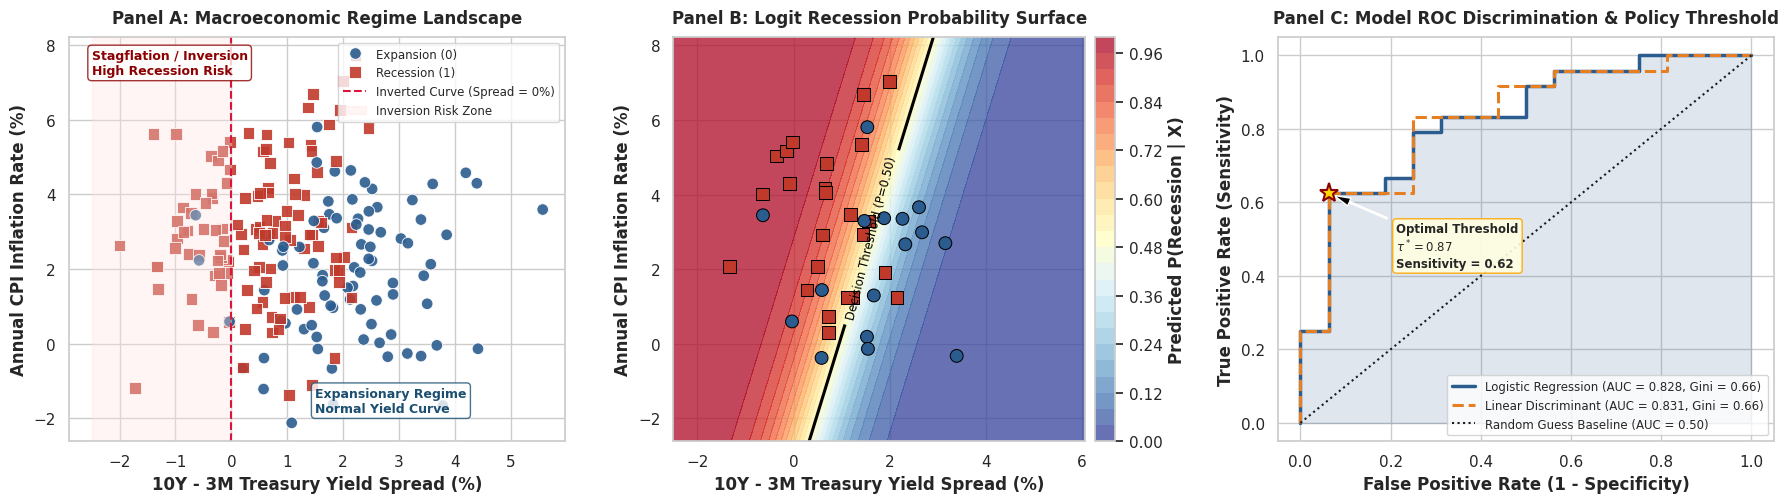

In [ ]:
# Worked Example: Macroeconomic Recession Classification with Logistic Regression & LDA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay

# Set seaborn theme for publication-quality visuals
sns.set_theme(style='whitegrid', font_scale=1.0)

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Generate synthetic macroeconomic panel dataset (n=200 quarters)
n_samples = 200
yield_spread = rng.normal(loc=1.2, scale=1.5, size=n_samples)
inflation = rng.normal(loc=2.5, scale=1.8, size=n_samples)
unemployment = rng.normal(loc=5.5, scale=2.0, size=n_samples)

# True recession mechanism: inverted yield curve (<0) + high inflation/unemployment
logit_score = -1.5 - 1.8 * yield_spread + 0.6 * inflation + 0.5 * unemployment
recession_prob = 1 / (1 + np.exp(-logit_score))
recession = rng.binomial(1, recession_prob)

df_macro = pd.DataFrame({
    'Yield_Spread': yield_spread,
    'Inflation': inflation,
    'Unemployment': unemployment,
    'Recession': recession
})
df_macro['Regime_Label'] = df_macro['Recession'].map({0: 'Expansion (0)', 1: 'Recession (1)'})

# Split into training and testing sets (80/20 stratified split)
X = df_macro[['Yield_Spread', 'Inflation', 'Unemployment']]
y = df_macro['Recession']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Fit Logistic Regression and LDA
logit_model = LogisticRegression(random_state=42)
logit_model.fit(X_train, y_train)

lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train, y_train)

# Predict probabilities on test set
y_prob_logit = logit_model.predict_proba(X_test)[:, 1]
y_prob_lda = lda_model.predict_proba(X_test)[:, 1]

# Compute ROC-AUC Scores & Gini coefficients
auc_logit = roc_auc_score(y_test, y_prob_logit)
auc_lda = roc_auc_score(y_test, y_prob_lda)
gini_logit = 2 * auc_logit - 1
gini_lda = 2 * auc_lda - 1

print(f"Logistic Regression  -> ROC-AUC: {auc_logit:.4f} | Gini: {gini_logit:.4f}")
print(f"Linear Discriminant  -> ROC-AUC: {auc_lda:.4f} | Gini: {gini_lda:.4f}")

# 3-Panel Visualisation: Economic Regimes, Probability Contours, and ROC Discrimination
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel 1: Macroeconomic Landscape & Historical Regimes
palette_regime = {'Expansion (0)': '#2b5c8f', 'Recession (1)': '#c0392b'}
sns.scatterplot(
    data=df_macro, x='Yield_Spread', y='Inflation', hue='Regime_Label',
    palette=palette_regime, style='Regime_Label', markers={'Expansion (0)': 'o', 'Recession (1)': 's'},
    s=70, edgecolor='white', alpha=0.9, ax=axes[0]
)
axes[0].axvline(0, color='crimson', linestyle='--', lw=1.5, label='Inverted Curve (Spread = 0%)')
axes[0].axvspan(df_macro['Yield_Spread'].min() - 0.5, 0, color='mistyrose', alpha=0.35, label='Inversion Risk Zone')
axes[0].text(-2.5, df_macro['Inflation'].max() - 0.5, 'Stagflation / Inversion\nHigh Recession Risk',
             fontsize=9, color='#8b0000', fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#8b0000', alpha=0.8))
axes[0].text(1.5, df_macro['Inflation'].min() + 0.3, 'Expansionary Regime\nNormal Yield Curve',
             fontsize=9, color='#1b4f72', fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#1b4f72', alpha=0.8))
axes[0].set_title('Panel A: Macroeconomic Regime Landscape', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('10Y - 3M Treasury Yield Spread (%)', fontweight='bold')
axes[0].set_ylabel('Annual CPI Inflation Rate (%)', fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, fontsize=8.5)

# Panel 2: Calibrated Recession Probability Surface (Logit Model)
xx, yy = np.meshgrid(
    np.linspace(X['Yield_Spread'].min() - 0.5, X['Yield_Spread'].max() + 0.5, 120),
    np.linspace(X['Inflation'].min() - 0.5, X['Inflation'].max() + 0.5, 120)
)
grid_X = pd.DataFrame({
    'Yield_Spread': xx.ravel(),
    'Inflation': yy.ravel(),
    'Unemployment': X_train['Unemployment'].mean()
})
zz_logit = logit_model.predict_proba(grid_X)[:, 1].reshape(xx.shape)

cnt = axes[1].contourf(xx, yy, zz_logit, levels=25, cmap='RdYlBu_r', alpha=0.75)
cbar = plt.colorbar(cnt, ax=axes[1], pad=0.02)
cbar.set_label('Predicted P(Recession | X)', fontweight='bold')

# Highlight the 50% policy decision boundary
cs = axes[1].contour(xx, yy, zz_logit, levels=[0.5], colors=['black'], linewidths=2.2, linestyles='-')
axes[1].clabel(cs, fmt='Decision Threshold (P=0.50)', inline=True, fontsize=8.5)

# Overlay test set points
df_test = df_macro.iloc[X_test.index]
sns.scatterplot(
    data=df_test, x='Yield_Spread', y='Inflation', hue='Regime_Label',
    palette=palette_regime, style='Regime_Label', markers={'Expansion (0)': 'o', 'Recession (1)': 's'},
    s=85, edgecolor='black', ax=axes[1], legend=False
)
axes[1].set_title('Panel B: Logit Recession Probability Surface', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('10Y - 3M Treasury Yield Spread (%)', fontweight='bold')
axes[1].set_ylabel('Annual CPI Inflation Rate (%)', fontweight='bold')

# Panel 3: ROC Discrimination & Optimal Youden Cutoff
fpr_l, tpr_l, thresholds_l = roc_curve(y_test, y_prob_logit)
fpr_lda, tpr_lda, _ = roc_curve(y_test, y_prob_lda)

# Identify Youden's optimal threshold: max(TPR - FPR)
youden_idx = np.argmax(tpr_l - fpr_l)
opt_fpr, opt_tpr = fpr_l[youden_idx], tpr_l[youden_idx]
opt_thresh = thresholds_l[youden_idx]

axes[2].fill_between(fpr_l, tpr_l, alpha=0.15, color='#2b5c8f')
axes[2].plot(fpr_l, tpr_l, label=f'Logistic Regression (AUC = {auc_logit:.3f}, Gini = {gini_logit:.2f})', color='#2b5c8f', lw=2.5)
axes[2].plot(fpr_lda, tpr_lda, label=f'Linear Discriminant (AUC = {auc_lda:.3f}, Gini = {gini_lda:.2f})', color='#e67e22', lw=2.2, linestyle='--')
axes[2].plot([0, 1], [0, 1], 'k:', lw=1.5, label='Random Guess Baseline (AUC = 0.50)')

# Star marker at Youden's optimal point
axes[2].plot(opt_fpr, opt_tpr, marker='*', markersize=14, color='gold', markeredgecolor='darkred', markeredgewidth=1.5, zorder=5)
axes[2].annotate(
    f'Optimal Threshold\n$\\tau^* = {opt_thresh:.2f}$\nSensitivity = {opt_tpr:.2f}',
    xy=(opt_fpr, opt_tpr), xytext=(opt_fpr + 0.15, opt_tpr - 0.20),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
    fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='orange', alpha=0.9)
)

axes[2].set_title('Panel C: Model ROC Discrimination & Policy Threshold', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
axes[2].set_ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
axes[2].legend(loc='lower right', frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

In [ ]:
def classify_sovereign_debt_distress(seed: int = 101) -> dict:
    """
    Sovereign Debt Distress Classification:
    Logistic Regression vs Linear Discriminant Analysis

    Returns
    -------
    dict
        {
            'df_sovereign',
            'logit_model',
            'lda_model',
            'auc_logit',
            'auc_lda',
            'confusion_matrix_logit',
            'test_size'
        }
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    from sklearn.model_selection import train_test_split
    from sklearn.linear_model import LogisticRegression
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

    from sklearn.metrics import (
        confusion_matrix,
        roc_curve,
        roc_auc_score,
        ConfusionMatrixDisplay
    )

    # --------------------------------------------------
    # 1. Generate Synthetic Sovereign Dataset
    # --------------------------------------------------

    rng = np.random.default_rng(seed)

    n = 150

    debt_to_gdp = rng.normal(65.0, 25.0, n)

    current_account = rng.normal(-2.0, 4.0, n)

    inflation = rng.normal(4.0, 3.0, n)

    governance = rng.normal(0.0, 1.0, n)

    # Latent sovereign distress mechanism
    latent_score = (
        -4.0
        + 0.045 * debt_to_gdp
        - 0.25 * current_account
        + 0.18 * inflation
        - 1.10 * governance
    )

    distress_prob = 1 / (1 + np.exp(-latent_score))

    debt_distress = rng.binomial(
        1,
        distress_prob
    )

    df_sovereign = pd.DataFrame({
        "Debt_to_GDP": debt_to_gdp,
        "Current_Account": current_account,
        "Inflation": inflation,
        "Governance_Index": governance,
        "Debt_Distress": debt_distress
    })

    # --------------------------------------------------
    # 2. Split Data
    # --------------------------------------------------

    X = df_sovereign[
        [
            "Debt_to_GDP",
            "Current_Account",
            "Inflation",
            "Governance_Index"
        ]
    ]

    y = df_sovereign["Debt_Distress"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=42
    )

    # --------------------------------------------------
    # 3. Fit Models
    # --------------------------------------------------

    logit_model = LogisticRegression(
        C=1.0,
        random_state=42,
        max_iter=1000
    )

    logit_model.fit(X_train, y_train)

    lda_model = LinearDiscriminantAnalysis()

    lda_model.fit(X_train, y_train)

    # --------------------------------------------------
    # 4. Predictions
    # --------------------------------------------------

    y_pred_logit = logit_model.predict(X_test)

    y_prob_logit = logit_model.predict_proba(X_test)[:, 1]

    y_prob_lda = lda_model.predict_proba(X_test)[:, 1]

    # --------------------------------------------------
    # 5. Evaluation Metrics
    # --------------------------------------------------

    cm_logit = confusion_matrix(
        y_test,
        y_pred_logit
    )

    auc_logit = roc_auc_score(
        y_test,
        y_prob_logit
    )

    auc_lda = roc_auc_score(
        y_test,
        y_prob_lda
    )

    # --------------------------------------------------
    # 6. ROC Curves
    # --------------------------------------------------

    fpr_logit, tpr_logit, _ = roc_curve(
        y_test,
        y_prob_logit
    )

    fpr_lda, tpr_lda, _ = roc_curve(
        y_test,
        y_prob_lda
    )

    # --------------------------------------------------
    # 7. Publication-Quality Figure
    # --------------------------------------------------

    sns.set_theme(
        style="whitegrid",
        font_scale=1.0
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5.5)
    )

    # ---------------- Panel A ----------------

    ConfusionMatrixDisplay(
        confusion_matrix=cm_logit,
        display_labels=[
            "Stable",
            "Distress"
        ]
    ).plot(
        cmap="Blues",
        ax=axes[0],
        colorbar=False
    )

    axes[0].set_title(
        "Panel A: Logistic Regression\nConfusion Matrix",
        fontweight="bold"
    )

    # ---------------- Panel B ----------------

    axes[1].plot(
        fpr_logit,
        tpr_logit,
        linewidth=2.5,
        color="#1f77b4",
        label=f"Logistic Regression (AUC={auc_logit:.3f})"
    )

    axes[1].plot(
        fpr_lda,
        tpr_lda,
        linewidth=2.5,
        linestyle="--",
        color="#e67e22",
        label=f"LDA (AUC={auc_lda:.3f})"
    )

    axes[1].plot(
        [0, 1],
        [0, 1],
        "k:",
        linewidth=1.5,
        label="Random Baseline"
    )

    axes[1].set_title(
        "Panel B: ROC Curve Comparison",
        fontweight="bold"
    )

    axes[1].set_xlabel(
        "False Positive Rate"
    )

    axes[1].set_ylabel(
        "True Positive Rate"
    )

    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # 8. Return Results
    # --------------------------------------------------

    return {
        "df_sovereign": df_sovereign,
        "logit_model": logit_model,
        "lda_model": lda_model,
        "auc_logit": auc_logit,
        "auc_lda": auc_lda,
        "confusion_matrix_logit": cm_logit,
        "test_size": len(y_test)
    }

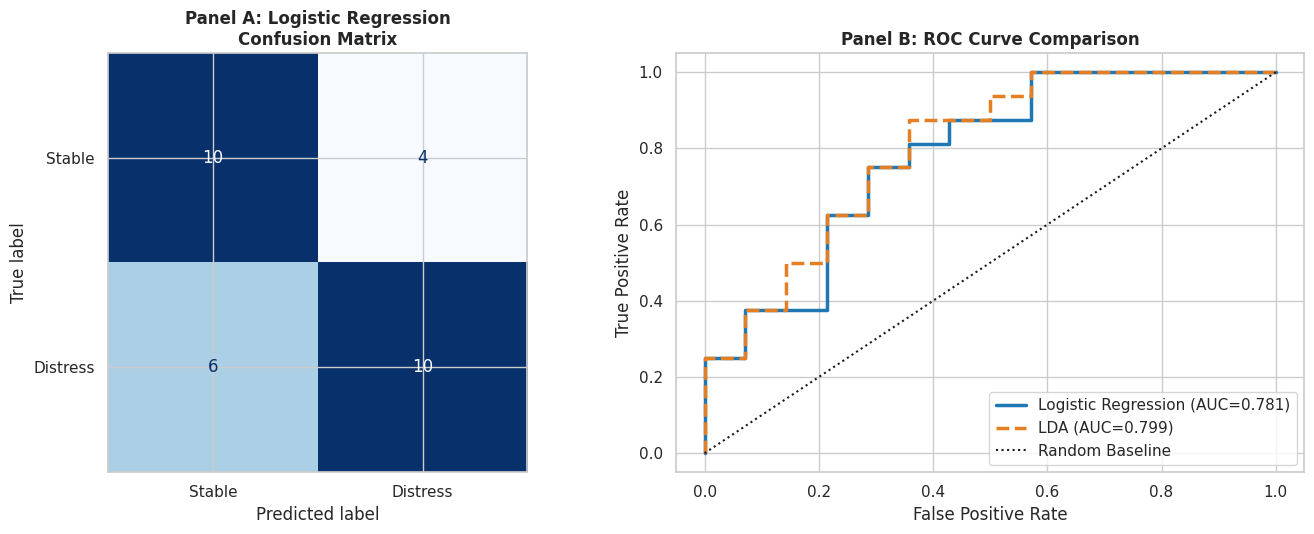

=== Sovereign Debt Distress Classification Results ===
Test Set Size: 30 economies
Logistic Regression ROC-AUC: 0.7812
Linear Discriminant Analysis ROC-AUC: 0.7991

=== Logistic Regression Confusion Matrix ===


,Pred Safe (0),Pred Distress (1)
Actual Safe (0),10,4
Actual Distress (1),6,10



=== Sample of Simulated Sovereign Dataset ===


,Debt_to_GDP,Current_Account,Inflation,Governance_Index,Debt_Distress
0,45.246188,-2.664247,5.745644,-0.806011,0
1,14.134363,-1.005266,11.210576,-0.325481,0
2,80.082544,-8.423988,-0.916704,0.096978,1
3,83.607363,-5.529769,-2.016071,1.505758,1
4,57.257830,-7.225686,4.266212,-0.688372,1


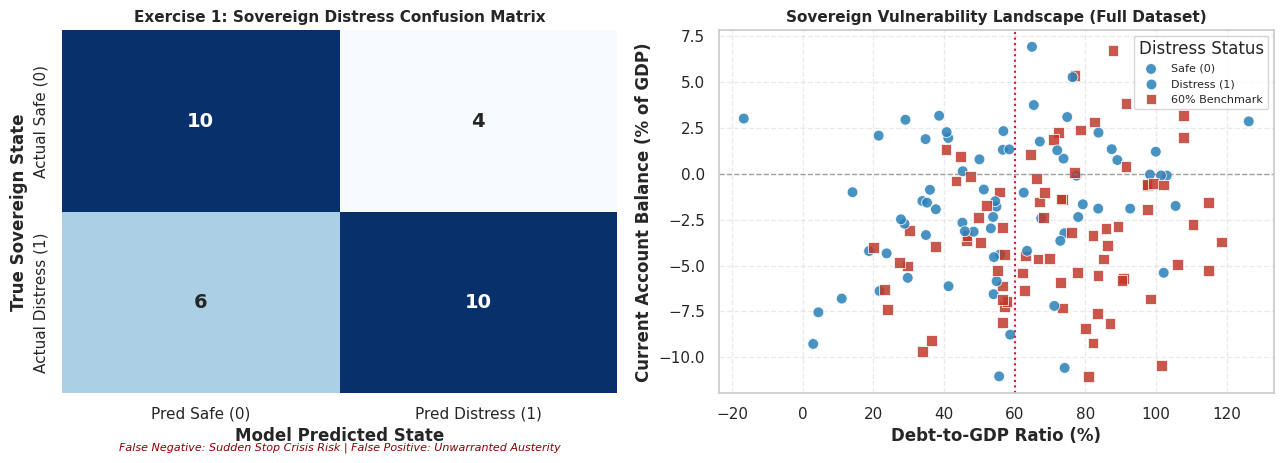

In [ ]:
# Output Inspection: Exercise 1
# Run your function and inspect sovereign classification performance and ROC-AUC

sov_results = classify_sovereign_debt_distress(seed=101)

if sov_results is not None:
    print("=== Sovereign Debt Distress Classification Results ===")
    print(f"Test Set Size: {sov_results['test_size']} economies")
    print(f"Logistic Regression ROC-AUC: {sov_results['auc_logit']:.4f}")
    print(f"Linear Discriminant Analysis ROC-AUC: {sov_results['auc_lda']:.4f}")

    print("\n=== Logistic Regression Confusion Matrix ===")
    cm_df = pd.DataFrame(
        sov_results['confusion_matrix_logit'],
        index=['Actual Safe (0)', 'Actual Distress (1)'],
        columns=['Pred Safe (0)', 'Pred Distress (1)']
    )
    display(cm_df)

    print("\n=== Sample of Simulated Sovereign Dataset ===")
    display(sov_results['df_sovereign'].head())

    # Visual Inspection Dashboard: Confusion Matrix Heatmap & Debt Vulnerability Distribution
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

    # Panel A: Confusion Matrix Heatmap with Economic Error Interpretations
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0], annot_kws={'size': 14, 'weight': 'bold'})
    axes[0].set_title('Exercise 1: Sovereign Distress Confusion Matrix', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('True Sovereign State', fontweight='bold')
    axes[0].set_xlabel('Model Predicted State', fontweight='bold')
    axes[0].text(0.5, -0.15, 'False Negative: Sudden Stop Crisis Risk | False Positive: Unwarranted Austerity',
                 ha='center', va='center', transform=axes[0].transAxes, fontsize=8.0, color='#8b0000', style='italic')

    # Panel B: Sovereign Debt-to-GDP vs Current Account Vulnerability Landscape
    palette_sov = {0: '#2980b9', 1: '#c0392b'}
    sns.scatterplot(
        data=sov_results['df_sovereign'], x='Debt_to_GDP', y='Current_Account',
        hue='Debt_Distress', palette=palette_sov, style='Debt_Distress',
        markers=['o', 's'], s=60, alpha=0.85, edgecolor='white', ax=axes[1]
    )
    axes[1].axhline(0, color='gray', linestyle='--', lw=1, alpha=0.7)
    axes[1].axvline(60, color='crimson', linestyle=':', lw=1.5, label='Maastricht Benchmark (60% GDP)')
    axes[1].set_title('Sovereign Vulnerability Landscape (Full Dataset)', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Debt-to-GDP Ratio (%)', fontweight='bold')
    axes[1].set_ylabel('Current Account Balance (% of GDP)', fontweight='bold')
    axes[1].legend(title='Distress Status', labels=['Safe (0)', 'Distress (1)', '60% Benchmark'], loc='upper right', fontsize=8.0)
    axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()
else:
    print("Function classify_sovereign_debt_distress returned None.")
    print("Implement your solution in the workspace cell above and re-run this cell to inspect results and visualizations!")

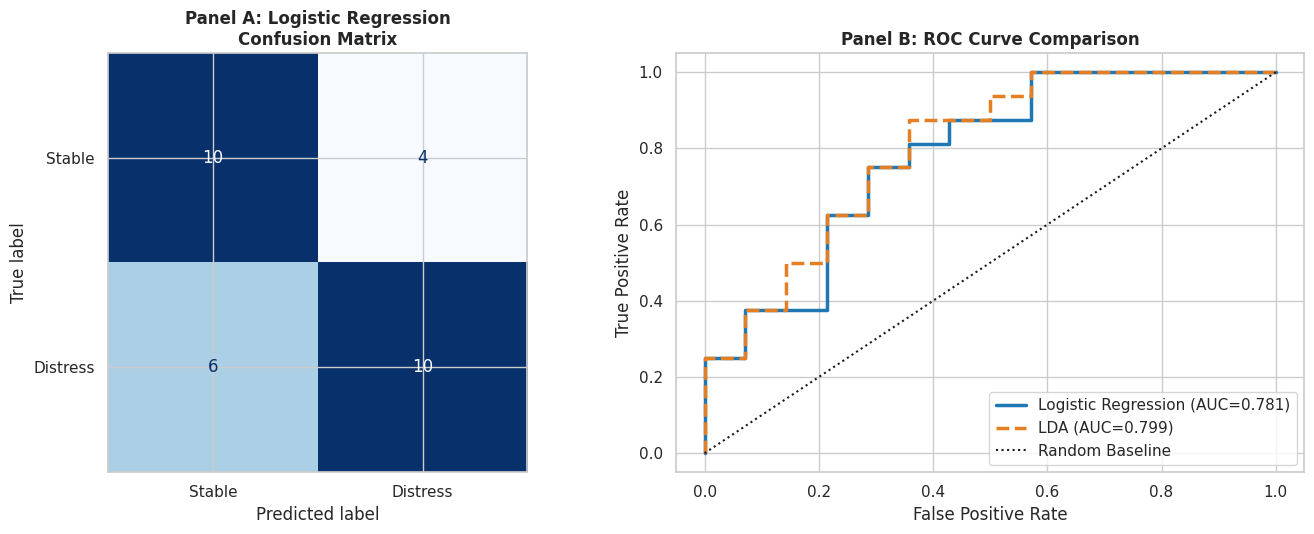

Exercise 1 validation passed successfully! All classification, AUC, and confusion matrix assertions confirmed.


In [ ]:
# Automated Validation Test: Exercise 1
# Do not modify this cell. Run it to verify your implementation.

test_sov = classify_sovereign_debt_distress(seed=101)

assert isinstance(test_sov, dict), "classify_sovereign_debt_distress must return a dict."
required_keys = {'df_sovereign', 'logit_model', 'lda_model', 'auc_logit', 'auc_lda', 'confusion_matrix_logit', 'test_size'}
assert required_keys.issubset(test_sov.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Check data shape and test split
assert test_sov['df_sovereign'].shape == (150, 5), f"Expected shape (150, 5), got {test_sov['df_sovereign'].shape}"
assert test_sov['test_size'] == 30, f"Expected test set size of 30, got {test_sov['test_size']}"

# 2. Check models and AUC performance
assert test_sov['auc_logit'] > 0.70, f"Expected Logistic Regression AUC > 0.70, got {test_sov['auc_logit']:.4f}"
assert test_sov['auc_lda'] > 0.70, f"Expected LDA AUC > 0.70, got {test_sov['auc_lda']:.4f}"

# 3. Check confusion matrix structure
cm = test_sov['confusion_matrix_logit']
assert isinstance(cm, np.ndarray) and cm.shape == (2, 2), "confusion_matrix_logit must be a 2x2 ndarray."
assert cm.sum() == 30, f"Confusion matrix total elements must equal test size 30, got {cm.sum()}"

print("Exercise 1 validation passed successfully! All classification, AUC, and confusion matrix assertions confirmed.")


1. Code Logic & ML Mechanics:
Stratified splitting is important because it preserves the proportion of distressed and non-distressed countries in both the training and test sets. If only 15% of economies experience default, a random split may create an unbalanced sample with too few crisis cases, leading to unreliable model training and evaluation.
2. Empirical Econometrics & Economic Policy Interpretation:
A False Negative is more dangerous because it classifies a distressed country as safe. This can delay intervention and increase the risk of sovereign default and financial instability. A False Positive mainly leads to additional monitoring, which is usually less costly. Policymakers can lower the classification threshold (for example, from 0.5 to 0.3) to identify more potential crises, increasing recall while accepting more false alarms.
3. AI Collaboration & ML Auditing:
Accuracy can be misleading for rare events such as debt crises. For example, if only 10% of countries are in distress, a model that predicts every country as safe would still achieve 90% accuracy. Therefore, it is better to report metrics such as Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC, which provide a more complete assessment of model performance.

=== Preprocessing Pipeline Transformation Summary ===
Transformed Feature Matrix Shape: (300, 6)
Pipeline Features: ['Income', 'Education_Years', 'Unemployment_Rate', 'Region_North', 'Region_South', 'Region_West']
Missing Values Before: 15 | Missing Values After: 0


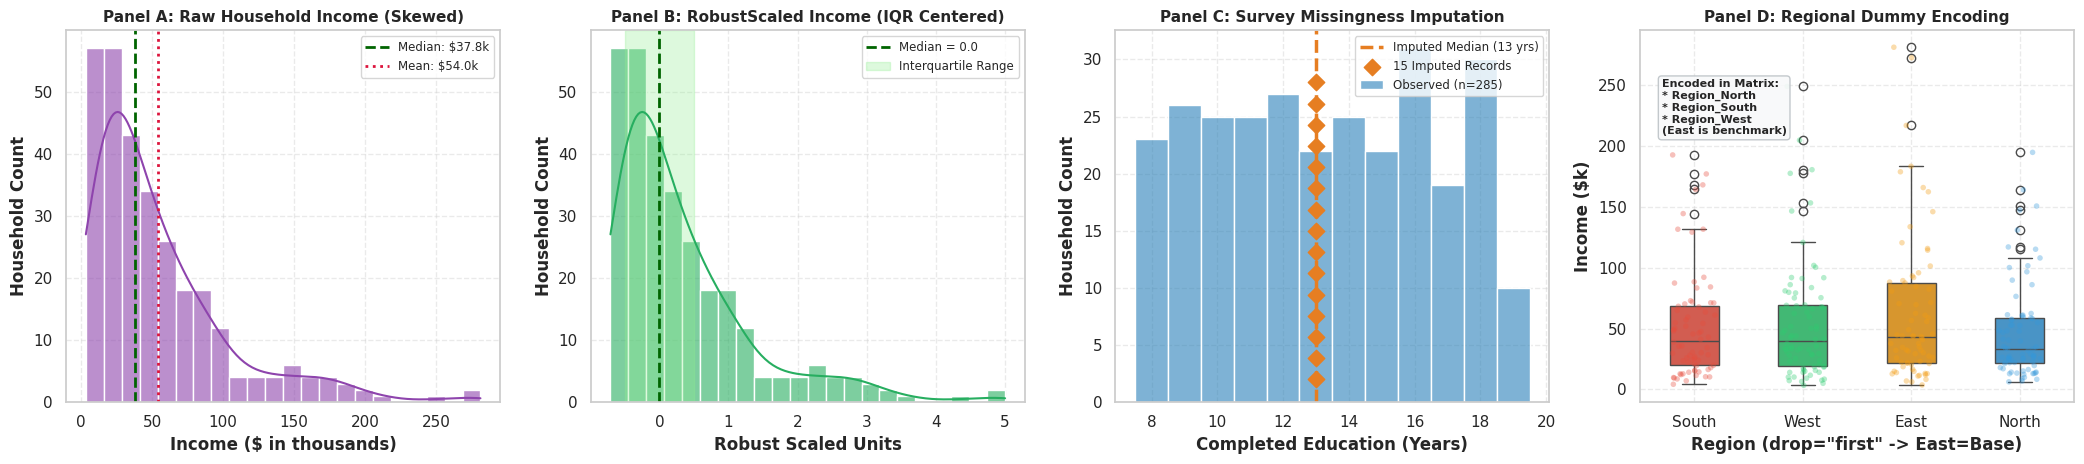


Transformed Feature Matrix Preview (First 5 Rows):


,Income,Education_Years,Unemployment_Rate,Region_North,Region_South,Region_West
0,0.687,-0.8,-0.578,0.0,1.0,0.0
1,-0.708,1.2,0.682,0.0,0.0,1.0
2,-0.192,-0.6,0.358,0.0,1.0,0.0
3,1.604,-0.8,-0.055,0.0,0.0,0.0
4,-0.501,0.6,-0.631,1.0,0.0,0.0


In [5]:
# Worked Example: Preprocessing Pipeline for Regional Socio-Economic Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder

# Set random seed for reproducibility
rng = np.random.default_rng(55)
n = 300

income = rng.lognormal(mean=10.5, sigma=0.8, size=n) # Right-skewed household income
education_years = rng.integers(low=8, high=20, size=n).astype(float)
# Introduce 15 random missing survey responses in education
missing_indices = rng.choice(n, size=15, replace=False)
education_years[missing_indices] = np.nan
unemp_rate = rng.uniform(low=2.0, high=15.0, size=n)
region = rng.choice(['North', 'South', 'East', 'West'], size=n)

df_survey = pd.DataFrame({
    'Income': income,
    'Education_Years': education_years,
    'Unemployment_Rate': unemp_rate,
    'Region': region
})

# Define numerical and categorical feature pipelines
num_features = ['Income', 'Education_Years', 'Unemployment_Rate']
cat_features = ['Region']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()) # Handles income outliers using median & IQR
])

cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

# Fit and transform the dataset
X_processed = preprocessor.fit_transform(df_survey)
encoded_cat_names = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(cat_features)
all_feature_names = num_features + list(encoded_cat_names)

df_processed = pd.DataFrame(X_processed, columns=all_feature_names)

print("=== Preprocessing Pipeline Transformation Summary ===")
print("Transformed Feature Matrix Shape:", df_processed.shape)
print("Pipeline Features:", all_feature_names)
print(f"Missing Values Before: {df_survey.isnull().sum().sum()} | Missing Values After: {df_processed.isnull().sum().sum()}")

# 4-Panel Diagnostic Dashboard: Raw vs Scaled, Imputation, and Categorical Encoding
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))

# Panel 1: Raw Skewed Household Income
sns.histplot(df_survey['Income'] / 1000, kde=True, ax=axes[0], color='#8e44ad', bins=22, alpha=0.6)
raw_med = df_survey['Income'].median() / 1000
raw_mean = df_survey['Income'].mean() / 1000
axes[0].axvline(raw_med, color='darkgreen', linestyle='--', lw=2, label=f'Median: ${raw_med:.1f}k')
axes[0].axvline(raw_mean, color='crimson', linestyle=':', lw=2, label=f'Mean: ${raw_mean:.1f}k')
axes[0].set_title('Panel A: Raw Household Income (Skewed)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Income ($ in thousands)', fontweight='bold')
axes[0].set_ylabel('Household Count', fontweight='bold')
axes[0].legend(loc='upper right', fontsize=8.5)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Panel 2: RobustScaled Income (Normalized Outliers)
sns.histplot(df_processed['Income'], kde=True, ax=axes[1], color='#27ae60', bins=22, alpha=0.6)
axes[1].axvline(0, color='darkgreen', linestyle='--', lw=2, label='Median = 0.0')
axes[1].axvspan(-0.5, 0.5, color='lightgreen', alpha=0.3, label='Interquartile Range')
axes[1].set_title('Panel B: RobustScaled Income (IQR Centered)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Robust Scaled Units', fontweight='bold')
axes[1].set_ylabel('Household Count', fontweight='bold')
axes[1].legend(loc='upper right', fontsize=8.5)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Panel 3: Imputation Diagnostic on Education Years
median_edu = df_survey['Education_Years'].median()
sns.histplot(df_survey['Education_Years'].dropna(), ax=axes[2], color='#2980b9', bins=12, discrete=True, alpha=0.6, label='Observed (n=285)')
axes[2].axvline(median_edu, color='#e67e22', linestyle='--', lw=2.5, label=f'Imputed Median ({median_edu:.0f} yrs)')
axes[2].scatter([median_edu] * len(missing_indices), np.linspace(2, 28, len(missing_indices)),
                color='#e67e22', s=70, marker='D', zorder=5, label=f'15 Imputed Records')
axes[2].set_title('Panel C: Survey Missingness Imputation', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Completed Education (Years)', fontweight='bold')
axes[2].set_ylabel('Household Count', fontweight='bold')
axes[2].legend(loc='upper right', fontsize=8.5)
axes[2].grid(True, linestyle='--', alpha=0.4)

# Panel 4: Categorical Regional Structure & Dummy Indicators
palette_regions = {'North': '#3498db', 'South': '#e74c3c', 'East': '#f39c12', 'West': '#2ecc71'}
sns.boxplot(data=df_survey, x='Region', y=df_survey['Income'] / 1000, hue='Region', palette=palette_regions, ax=axes[3], width=0.45, legend=False)
sns.stripplot(data=df_survey, x='Region', y=df_survey['Income'] / 1000, hue='Region', palette=palette_regions, alpha=0.35, size=4, jitter=0.2, ax=axes[3], legend=False)
axes[3].set_title('Panel D: Regional Dummy Encoding', fontsize=11, fontweight='bold')
axes[3].set_xlabel('Region (drop="first" -> East=Base)', fontweight='bold')
axes[3].set_ylabel('Income ($k)', fontweight='bold')
axes[3].text(0.05, 0.72, 'Encoded in Matrix:\n* Region_North\n* Region_South\n* Region_West\n(East is benchmark)',
             transform=axes[3].transAxes, fontsize=8.0, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.3', fc='#f8f9fa', ec='#bdc3c7', alpha=0.9))
axes[3].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print("\nTransformed Feature Matrix Preview (First 5 Rows):")
display(df_processed.head().round(3))

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def build_regional_labor_pipeline(seed: int = 2024) -> tuple:
    """
    Construct and apply a scikit-learn ColumnTransformer preprocessing pipeline
    for regional labor and economic indicators.

    Parameters
    ----------
    seed : int, default=2024
        Random seed for reproducibility.

    Returns
    -------
    tuple[pd.DataFrame, ColumnTransformer]
        df_transformed : transformed feature matrix
        preprocessor_pipeline : fitted ColumnTransformer
    """

    # --------------------------------------------------
    # 1. Generate synthetic regional dataset
    # --------------------------------------------------
    rng = np.random.default_rng(seed)
    n = 250

    regional_gdp = rng.lognormal(
        mean=8.0,
        sigma=1.0,
        size=n
    )

    labor_participation = rng.normal(
        loc=65.0,
        scale=8.0,
        size=n
    )

    edu_expenditure = rng.normal(
        loc=3500,
        scale=800,
        size=n
    )

    # Exactly 20 missing observations
    missing_idx = rng.choice(
        n,
        size=20,
        replace=False
    )

    edu_expenditure[missing_idx] = np.nan

    economic_sector = rng.choice(
        ['Agriculture', 'Manufacturing', 'Services'],
        size=n
    )

    df = pd.DataFrame({
        "Regional_GDP": regional_gdp,
        "Labor_Participation": labor_participation,
        "Edu_Expenditure": edu_expenditure,
        "Economic_Sector": economic_sector
    })

    # --------------------------------------------------
    # 2. Engineer interaction feature
    # --------------------------------------------------
    median_edu = df["Edu_Expenditure"].median()

    df["Edu_Labor_Interaction"] = (
        df["Edu_Expenditure"].fillna(median_edu)
        * df["Labor_Participation"]
    )

    # --------------------------------------------------
    # 3. Define feature groups
    # --------------------------------------------------
    numerical_features = [
        "Regional_GDP",
        "Labor_Participation",
        "Edu_Expenditure",
        "Edu_Labor_Interaction"
    ]

    categorical_features = [
        "Economic_Sector"
    ]

    # --------------------------------------------------
    # 4. Numerical pipeline
    # --------------------------------------------------
    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # --------------------------------------------------
    # 5. Categorical pipeline
    # --------------------------------------------------
    cat_pipeline = Pipeline([
        ("encoder",
         OneHotEncoder(
             drop="first",
             sparse_output=False
         ))
    ])

    # --------------------------------------------------
    # 6. ColumnTransformer
    # --------------------------------------------------
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, numerical_features),
        ("cat", cat_pipeline, categorical_features)
    ])

    # --------------------------------------------------
    # 7. Fit & Transform
    # --------------------------------------------------
    X_processed = preprocessor.fit_transform(df)

    encoded_names = (
        preprocessor
        .named_transformers_["cat"]
        .named_steps["encoder"]
        .get_feature_names_out(categorical_features)
    )

    transformed_columns = (
        numerical_features +
        list(encoded_names)
    )

    df_transformed = pd.DataFrame(
        X_processed,
        columns=transformed_columns
    )

    # --------------------------------------------------
    # 8. Visualization
    # --------------------------------------------------
    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 5)
    )

    # Panel A: Raw GDP
    sns.boxplot(
        y=df["Regional_GDP"],
        ax=axes[0],
        color="#5DADE2"
    )

    axes[0].set_title(
        "Panel A: Raw Regional GDP (Skewed)",
        fontweight="bold"
    )
    axes[0].set_ylabel("GDP ($ Millions)")
    axes[0].grid(alpha=0.3)

    # Panel B: Standardized GDP
    sns.boxplot(
        y=df_transformed["Regional_GDP"],
        ax=axes[1],
        color="#58D68D"
    )

    axes[1].set_title(
        "Panel B: Standardized GDP (Z-Scores)",
        fontweight="bold"
    )
    axes[1].set_ylabel("Standardized Units")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # 9. Summary output
    # --------------------------------------------------
    print("=== Regional Labor Market Pipeline Summary ===")
    print("Original Shape:", df.shape)
    print("Transformed Shape:", df_transformed.shape)

    print(
        f"Missing Values Before: "
        f"{df.isna().sum().sum()} | "
        f"Missing Values After: "
        f"{df_transformed.isna().sum().sum()}"
    )

    print("\nTransformed Features:")
    print(transformed_columns)

    return df_transformed, preprocessor

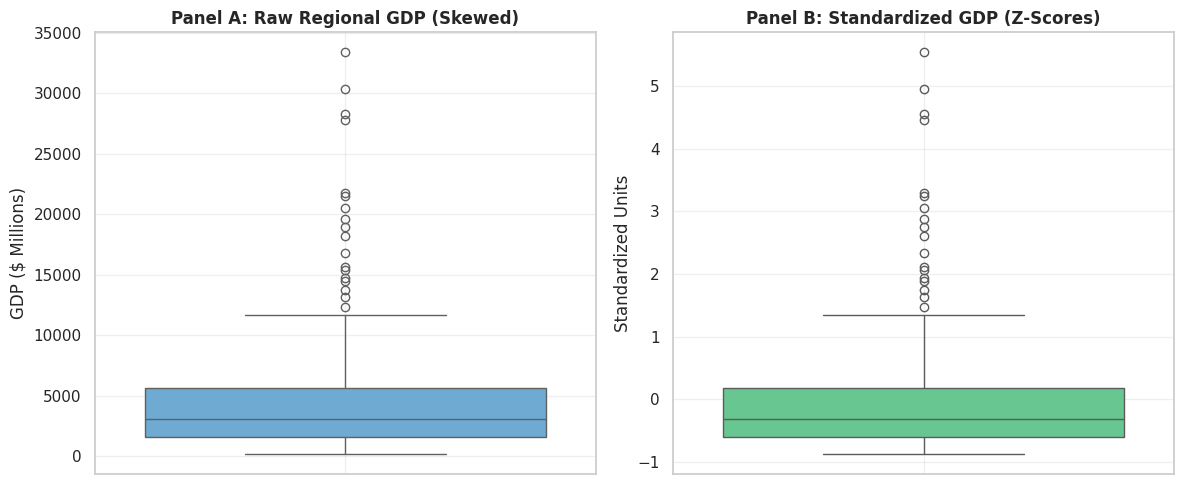

=== Regional Labor Market Pipeline Summary ===
Original Shape: (250, 5)
Transformed Shape: (250, 6)
Missing Values Before: 20 | Missing Values After: 0

Transformed Features:
['Regional_GDP', 'Labor_Participation', 'Edu_Expenditure', 'Edu_Labor_Interaction', 'Economic_Sector_Manufacturing', 'Economic_Sector_Services']
=== Preprocessed Regional Feature Matrix (First 5 Rows) ===


,Regional_GDP,Labor_Participation,Edu_Expenditure,Edu_Labor_Interaction,Economic_Sector_Manufacturing,Economic_Sector_Services
0,0.7075,-0.6136,-0.9298,-1.0076,0.0,1.0
1,2.0700,0.7802,0.2135,0.5509,0.0,0.0
2,0.9089,-0.0219,0.5208,0.4216,0.0,0.0
3,-0.6854,-0.4863,0.2769,-0.0097,0.0,0.0
4,-0.7599,-0.2659,-0.8007,-0.7770,1.0,0.0



=== Transformed Columns & Data Types ===
Regional_GDP                     float64
Labor_Participation              float64
Edu_Expenditure                  float64
Edu_Labor_Interaction            float64
Economic_Sector_Manufacturing    float64
Economic_Sector_Services         float64
dtype: object

=== Check for Missing Values Post-Pipeline ===
Total Missing Values Remaining: 0


/tmp/ipykernel_955/2338578881.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right', fontweight='bold')


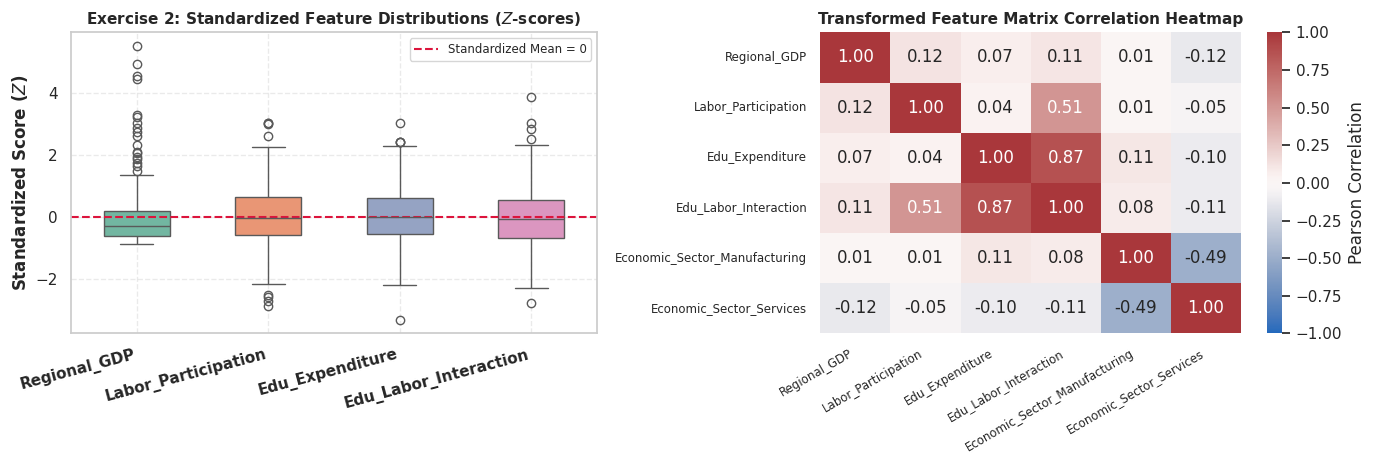

In [7]:
# Output Inspection: Exercise 2
# Run your function and inspect preprocessed pipeline features and distributions

df_transformed, labor_pipeline = build_regional_labor_pipeline(seed=2024)

if df_transformed is not None:
    print("=== Preprocessed Regional Feature Matrix (First 5 Rows) ===")
    display(df_transformed.head().round(4))

    print("\n=== Transformed Columns & Data Types ===")
    print(df_transformed.dtypes)

    print("\n=== Check for Missing Values Post-Pipeline ===")
    print(f"Total Missing Values Remaining: {df_transformed.isnull().sum().sum()}")

    # Visual Inspection Dashboard: Standardized Numerical Feature Distributions & Feature Correlations
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    # Panel A: Boxplots of Standardized Numerical Features (Mean ~ 0, Variance ~ 1)
    num_cols = [c for c in ['Regional_GDP', 'Labor_Participation', 'Edu_Expenditure', 'Edu_Labor_Interaction'] if c in df_transformed.columns]
    if num_cols:
        sns.boxplot(data=df_transformed[num_cols], palette='Set2', ax=axes[0], width=0.5)
        axes[0].axhline(0, color='crimson', linestyle='--', lw=1.5, label='Standardized Mean = 0')
        axes[0].set_title('Exercise 2: Standardized Feature Distributions ($Z$-scores)', fontsize=11, fontweight='bold')
        axes[0].set_ylabel('Standardized Score ($Z$)', fontweight='bold')
        axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right', fontweight='bold')
        axes[0].legend(loc='upper right', fontsize=8.5)
        axes[0].grid(True, linestyle='--', alpha=0.4)

    # Panel B: Correlation Heatmap Across Preprocessed Features
    corr_matrix = df_transformed.corr()
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0, ax=axes[1], cbar_kws={'label': 'Pearson Correlation'})
    axes[1].set_title('Transformed Feature Matrix Correlation Heatmap', fontsize=11, fontweight='bold')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right', fontsize=8.5)
    axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=8.5)

    plt.tight_layout()
    plt.show()
else:
    print("Function build_regional_labor_pipeline returned None.")
    print("Implement your solution in the workspace cell above and re-run this cell to inspect results and visualizations!")

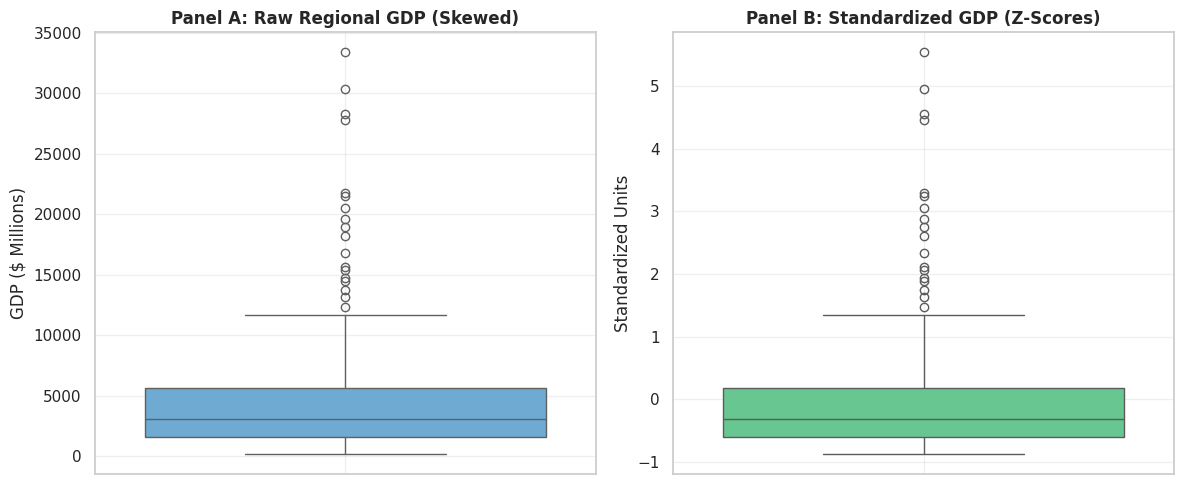

=== Regional Labor Market Pipeline Summary ===
Original Shape: (250, 5)
Transformed Shape: (250, 6)
Missing Values Before: 20 | Missing Values After: 0

Transformed Features:
['Regional_GDP', 'Labor_Participation', 'Edu_Expenditure', 'Edu_Labor_Interaction', 'Economic_Sector_Manufacturing', 'Economic_Sector_Services']
Exercise 2 validation passed successfully! All preprocessing pipeline and imputation assertions confirmed.


In [9]:
# Automated Validation Test: Exercise 2
# Do not modify this cell. Run it to verify your implementation.

test_df, test_pipe = build_regional_labor_pipeline(seed=2024)

# 1. Output types
assert isinstance(test_df, pd.DataFrame), "First return value must be a pd.DataFrame."
assert hasattr(test_pipe, 'transform'), "Second return value must be a fitted ColumnTransformer."

# 2. Dimensions and column count
# 4 numerical features + 2 dummy columns from Economic_Sector (with drop='first') = 6 columns
assert test_df.shape == (250, 6), f"Expected shape (250, 6), got {test_df.shape}"

# 3. Missing value integrity
assert not test_df.isnull().values.any(), "Transformed DataFrame must not contain any NaN or null values."

# 4. Standardization checks on numerical columns (mean ~ 0, std ~ 1)
num_check_cols = ['Regional_GDP', 'Labor_Participation', 'Edu_Expenditure', 'Edu_Labor_Interaction']
for col in num_check_cols:
    assert col in test_df.columns, f"Missing expected numerical column: {col}"
    assert np.isclose(test_df[col].mean(), 0.0, atol=1e-2), f"Standardized mean for {col} should be ~0, got {test_df[col].mean():.4f}"
    assert np.isclose(test_df[col].std(ddof=0), 1.0, atol=1e-2), f"Standardized std for {col} should be ~1, got {test_df[col].std(ddof=0):.4f}"

print("Exercise 2 validation passed successfully! All preprocessing pipeline and imputation assertions confirmed.")


In [ ]:
1. Code Logic & ML Mechanics
Using drop='first' helps prevent the dummy variable trap. If all categories are included as dummy variables, one category can be perfectly predicted from the others, creating multicollinearity. In linear and logistic regression, this can make the design matrix singular and cause problems when estimating coefficients.
For decision trees, this is less of an issue because trees do not estimate coefficients. Instead, they split data based on decision rules, so redundant dummy variables do not create the same mathematical problem.
2. Empirical Econometrics & Economic Policy Interpretation
Median imputation is usually preferred for economic variables because income, GDP, and education spending are often highly skewed and contain extreme values. The median is less affected by outliers than the mean, making it a more robust estimate.
However, if data are Missing Not at Random (MNAR), simple imputation can introduce bias. For example, if poorer regions are less likely to report their education expenditure, replacing missing values with the median may overestimate their actual spending. This can lead to selection bias and misleading policy conclusions.
3. AI Collaboration & ML Auditing
Using a Pipeline or ColumnTransformer is better because all preprocessing steps are stored in one reproducible workflow. This ensures that the same transformations are applied during training, testing, and deployment.
Pipelines also help prevent data leakage. During cross-validation, imputation and scaling are learned only from the training data and then applied to the validation data. Without a pipeline, information from the test set may accidentally influence preprocessing, leading to overly optimistic model performance estimates.

Random Forest      -> Test Accuracy: 0.9733 | Test F1-Score: 0.9565
Gradient Boosting  -> Test Accuracy: 0.9733 | Test F1-Score: 0.9565


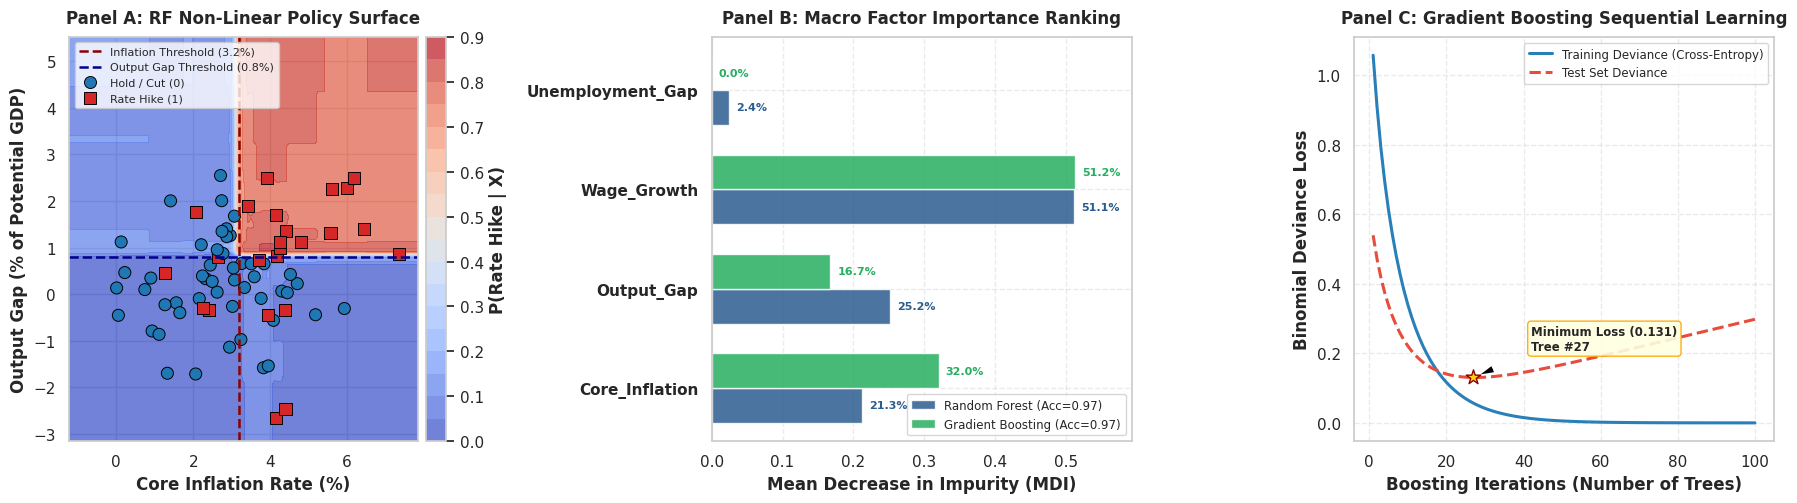

In [10]:
# Worked Example: Random Forest vs Gradient Boosting for Central Bank Policy Rate Hikes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

# Set random seed for reproducibility
rng = np.random.default_rng(88)
n = 300

core_inflation = rng.normal(loc=3.0, scale=1.5, size=n)
gdp_gap = rng.normal(loc=0.5, scale=1.2, size=n) # Output gap (% deviation from potential)
wage_growth = rng.normal(loc=3.5, scale=1.0, size=n)
unemp_gap = rng.normal(loc=-0.2, scale=1.0, size=n)

# Non-linear monetary policy rate hike decision rule (Taylor rule with threshold triggers)
hike_signal = (core_inflation > 3.2) & (gdp_gap > 0.8) | (wage_growth > 4.5)
rate_hike = hike_signal.astype(int)

df_cb = pd.DataFrame({
    'Core_Inflation': core_inflation,
    'Output_Gap': gdp_gap,
    'Wage_Growth': wage_growth,
    'Unemployment_Gap': unemp_gap,
    'Rate_Hike': rate_hike
})
df_cb['Decision_Label'] = df_cb['Rate_Hike'].map({0: 'Hold / Cut (0)', 1: 'Rate Hike (1)'})

X_cb = df_cb[['Core_Inflation', 'Output_Gap', 'Wage_Growth', 'Unemployment_Gap']]
y_cb = df_cb['Rate_Hike']

X_train, X_test, y_train, y_test = train_test_split(X_cb, y_cb, test_size=0.25, stratify=y_cb, random_state=42)

# Fit Random Forest & Gradient Boosting
rf_cb = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
rf_cb.fit(X_train, y_train)

gb_cb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_cb.fit(X_train, y_train)

# Evaluate classification performance
rf_acc = accuracy_score(y_test, rf_cb.predict(X_test))
rf_f1 = f1_score(y_test, rf_cb.predict(X_test))
gb_acc = accuracy_score(y_test, gb_cb.predict(X_test))
gb_f1 = f1_score(y_test, gb_cb.predict(X_test))

print(f"Random Forest      -> Test Accuracy: {rf_acc:.4f} | Test F1-Score: {rf_f1:.4f}")
print(f"Gradient Boosting  -> Test Accuracy: {gb_acc:.4f} | Test F1-Score: {gb_f1:.4f}")

# 3-Panel Visualisation: Decision Surface, Feature Importances, and Boosting Convergence
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel 1: Random Forest Non-Linear Policy Decision Surface
xx, yy = np.meshgrid(
    np.linspace(X_cb['Core_Inflation'].min() - 0.5, X_cb['Core_Inflation'].max() + 0.5, 120),
    np.linspace(X_cb['Output_Gap'].min() - 0.5, X_cb['Output_Gap'].max() + 0.5, 120)
)
grid_cb = pd.DataFrame({
    'Core_Inflation': xx.ravel(),
    'Output_Gap': yy.ravel(),
    'Wage_Growth': X_train['Wage_Growth'].mean(),
    'Unemployment_Gap': X_train['Unemployment_Gap'].mean()
})
zz_rf = rf_cb.predict_proba(grid_cb)[:, 1].reshape(xx.shape)

cnt = axes[0].contourf(xx, yy, zz_rf, levels=20, cmap='coolwarm', alpha=0.75)
cbar = plt.colorbar(cnt, ax=axes[0], pad=0.02)
cbar.set_label('P(Rate Hike | X)', fontweight='bold')

# Overlay policy threshold triggers
axes[0].axvline(3.2, color='darkred', linestyle='--', lw=1.8, label='Inflation Threshold (3.2%)')
axes[0].axhline(0.8, color='darkblue', linestyle='--', lw=1.8, label='Output Gap Threshold (0.8%)')

# Plot actual test policy meetings
palette_cb = {'Hold / Cut (0)': '#1f77b4', 'Rate Hike (1)': '#d62728'}
df_test_cb = df_cb.iloc[X_test.index]
sns.scatterplot(
    data=df_test_cb, x='Core_Inflation', y='Output_Gap', hue='Decision_Label',
    palette=palette_cb, style='Decision_Label', markers={'Hold / Cut (0)': 'o', 'Rate Hike (1)': 's'},
    s=75, edgecolor='black', ax=axes[0]
)
axes[0].set_title('Panel A: RF Non-Linear Policy Surface', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Core Inflation Rate (%)', fontweight='bold')
axes[0].set_ylabel('Output Gap (% of Potential GDP)', fontweight='bold')
axes[0].legend(loc='upper left', fontsize=8.0, frameon=True)

# Panel 2: Comparative Feature Importances (MDI)
df_imp = pd.DataFrame({
    'Feature': X_cb.columns,
    'Random Forest': rf_cb.feature_importances_,
    'Gradient Boosting': gb_cb.feature_importances_
}).melt(id_vars='Feature', var_name='Model', value_name='Importance')

y_pos = np.arange(len(X_cb.columns))
height = 0.35
axes[1].barh(y_pos - height/2, rf_cb.feature_importances_, height=height, label=f'Random Forest (Acc={rf_acc:.2f})', color='#2b5c8f', alpha=0.85)
axes[1].barh(y_pos + height/2, gb_cb.feature_importances_, height=height, label=f'Gradient Boosting (Acc={gb_acc:.2f})', color='#27ae60', alpha=0.85)

for i, (rf_val, gb_val) in enumerate(zip(rf_cb.feature_importances_, gb_cb.feature_importances_)):
    axes[1].text(rf_val + 0.01, i - height/2, f'{rf_val*100:.1f}%', va='center', fontsize=8.0, color='#2b5c8f', fontweight='bold')
    axes[1].text(gb_val + 0.01, i + height/2, f'{gb_val*100:.1f}%', va='center', fontsize=8.0, color='#27ae60', fontweight='bold')

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(X_cb.columns, fontweight='bold')
axes[1].set_xlim(0, max(max(rf_cb.feature_importances_), max(gb_cb.feature_importances_)) + 0.08)
axes[1].set_title('Panel B: Macro Factor Importance Ranking', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Mean Decrease in Impurity (MDI)', fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8.5, frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Panel 3: Gradient Boosting Stage-Wise Deviance Loss Reduction
test_deviance = [log_loss(y_test, prob) for prob in gb_cb.staged_predict_proba(X_test)]
train_deviance = gb_cb.train_score_

axes[2].plot(np.arange(1, 101), train_deviance, label='Training Deviance (Cross-Entropy)', color='#2980b9', lw=2.2)
axes[2].plot(np.arange(1, 101), test_deviance, label='Test Set Deviance', color='#e74c3c', lw=2.2, linestyle='--')

min_test_idx = np.argmin(test_deviance) + 1
min_test_val = np.min(test_deviance)
axes[2].scatter(min_test_idx, min_test_val, color='gold', edgecolor='darkred', s=120, zorder=5, marker='*')
axes[2].annotate(f'Minimum Loss ({min_test_val:.3f})\nTree #{min_test_idx}', xy=(min_test_idx, min_test_val),
                xytext=(min_test_idx + 15, min_test_val + 0.08),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
                fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='orange', alpha=0.9))

axes[2].set_title('Panel C: Gradient Boosting Sequential Learning', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Boosting Iterations (Number of Trees)', fontweight='bold')
axes[2].set_ylabel('Binomial Deviance Loss', fontweight='bold')
axes[2].legend(loc='upper right', fontsize=8.5, frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


def predict_regional_poverty(seed: int = 777) -> dict:
    """
    Predict High Poverty & Severe Inequality Regimes
    using Gradient Boosting.
    """

    # --------------------------------------------------
    # 1. Simulate regional data
    # --------------------------------------------------
    rng = np.random.default_rng(seed)
    n = 300

    urbanization = rng.uniform(20, 90, n)

    manufacturing = rng.uniform(5, 45, n)

    edu_spend = rng.normal(
        loc=1200,
        scale=350,
        size=n
    )

    tax_ratio = rng.normal(
        loc=18,
        scale=4,
        size=n
    )

    # --------------------------------------------------
    # 2. Non-linear poverty trap rule
    # --------------------------------------------------
    poverty_rule = (
        ((urbanization < 45) &
         (manufacturing < 18))
        |
        ((edu_spend < 1050) &
         (tax_ratio < 17))
        |
        ((urbanization < 35) &
         (edu_spend < 1000))
    )

    high_poverty = poverty_rule.astype(int)

    # --------------------------------------------------
    # 3. Build DataFrame
    # --------------------------------------------------
    df_poverty = pd.DataFrame({
        "Urbanization_Rate": urbanization,
        "Manufacturing_Share": manufacturing,
        "Edu_Spend_Per_Capita": edu_spend,
        "Tax_Revenue_Ratio": tax_ratio,
        "High_Poverty_Tier": high_poverty
    })

    # --------------------------------------------------
    # 4. Features and target
    # --------------------------------------------------
    X = df_poverty[
        [
            "Urbanization_Rate",
            "Manufacturing_Share",
            "Edu_Spend_Per_Capita",
            "Tax_Revenue_Ratio"
        ]
    ]

    y = df_poverty["High_Poverty_Tier"]

    # --------------------------------------------------
    # 5. Train/Test Split
    # --------------------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        stratify=y,
        random_state=42
    )

    # --------------------------------------------------
    # 6. Gradient Boosting
    # --------------------------------------------------
    gb = GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

    gb.fit(X_train, y_train)

    # --------------------------------------------------
    # 7. Predictions
    # --------------------------------------------------
    y_pred = gb.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    # --------------------------------------------------
    # 8. Feature Importances
    # --------------------------------------------------
    feature_importances = pd.Series(
        gb.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False)

    # --------------------------------------------------
    # 9. Publication-quality plot
    # --------------------------------------------------
    plt.figure(figsize=(8, 5))

    colors = [
        "#c0392b",
        "#e67e22",
        "#2980b9",
        "#27ae60"
    ]

    feature_importances.plot(
        kind="barh",
        color=colors[:len(feature_importances)]
    )

    plt.title(
        "Feature Importance Ranking\n(Gradient Boosting)",
        fontweight="bold"
    )

    plt.xlabel(
        "Mean Decrease in Impurity"
    )

    plt.ylabel(
        "Economic Fundamentals"
    )

    plt.gca().invert_yaxis()
    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.4
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # 10. Return results
    # --------------------------------------------------
    return {
        "model": gb,
        "accuracy": accuracy,
        "f1": f1,
        "feature_importances": feature_importances,
        "df_poverty": df_poverty
    }

Accuracy : 0.8933
Precision: 0.7826
Recall   : 0.8571
F1-Score : 0.8182


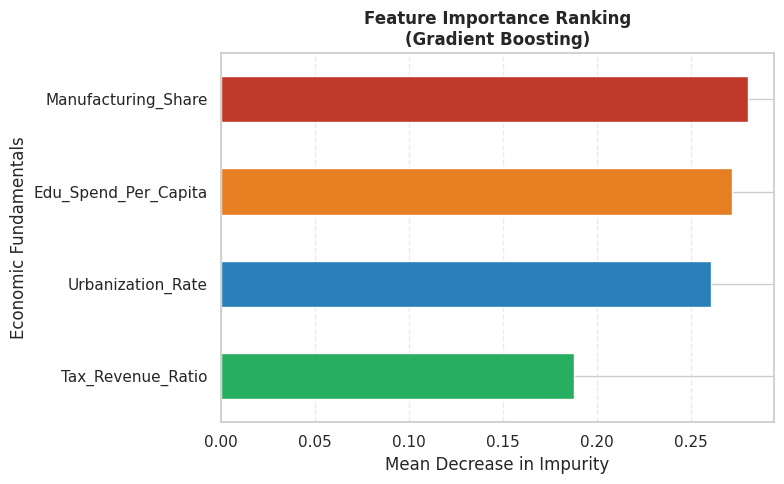

=== Regional Poverty Prediction Performance Metrics ===
Test Accuracy: 0.8933
Test F1-Score: 0.8182

=== Economic Feature Importances (MDI) ===


,Relative Importance
Manufacturing_Share,0.2800
Edu_Spend_Per_Capita,0.2715
Urbanization_Rate,0.2607
Tax_Revenue_Ratio,0.1877



=== Dataset Distribution Sample ===


,Urbanization_Rate,Manufacturing_Share,Edu_Spend_Per_Capita,Tax_Revenue_Ratio,High_Poverty_Tier
0,62.776575,42.565309,1030.589361,16.028133,1
1,46.797161,12.912117,1222.669487,20.848925,0
2,62.004937,44.263547,1313.384698,15.813076,0
3,87.449051,43.295725,1697.548920,14.150883,0
4,33.731379,35.485543,1710.444108,18.940251,0


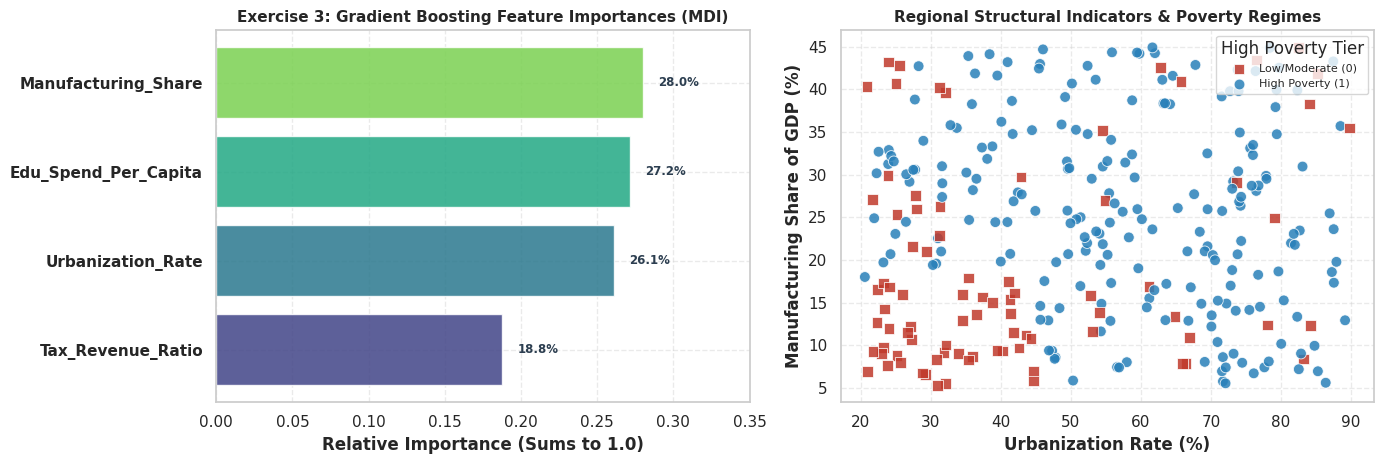

In [13]:
# Output Inspection: Exercise 3
# Run your function and inspect test classification metrics and feature importances

pov_results = predict_regional_poverty(seed=777)

if pov_results is not None:
    print("=== Regional Poverty Prediction Performance Metrics ===")
    print(f"Test Accuracy: {pov_results['accuracy']:.4f}")
    print(f"Test F1-Score: {pov_results['f1']:.4f}")

    print("\n=== Economic Feature Importances (MDI) ===")
    display(pov_results['feature_importances'].to_frame(name='Relative Importance').round(4))

    print("\n=== Dataset Distribution Sample ===")
    display(pov_results['df_poverty'].head())

    # Visual Inspection Dashboard: Feature Importance Ranking & Regional Poverty Spatial Distribution
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    # Panel A: Feature Importances Bar Chart
    fi_series = pov_results['feature_importances']
    colors_fi = sns.color_palette('viridis', n_colors=len(fi_series))[::-1]
    axes[0].barh(range(len(fi_series)), fi_series.values, color=colors_fi, alpha=0.85)
    axes[0].set_yticks(range(len(fi_series)))
    axes[0].set_yticklabels(fi_series.index, fontweight='bold')
    axes[0].set_xlim(0, max(fi_series.values) * 1.25)
    for i, v in enumerate(fi_series.values):
        axes[0].text(v + 0.01, i, f'{v*100:.1f}%', va='center', fontweight='bold', fontsize=8.5, color='#2c3e50')
    axes[0].set_title('Exercise 3: Gradient Boosting Feature Importances (MDI)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Relative Importance (Sums to 1.0)', fontweight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.4)
    axes[0].invert_yaxis()

    # Panel B: District Economic Fundamentals & High Poverty Incidence
    palette_pov = {0: '#2980b9', 1: '#c0392b'}
    sns.scatterplot(
        data=pov_results['df_poverty'], x='Urbanization_Rate', y='Manufacturing_Share',
        hue='High_Poverty_Tier', palette=palette_pov, style='High_Poverty_Tier',
        markers=['o', 's'], s=60, alpha=0.85, edgecolor='white', ax=axes[1]
    )
    axes[1].set_title('Regional Structural Indicators & Poverty Regimes', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Urbanization Rate (%)', fontweight='bold')
    axes[1].set_ylabel('Manufacturing Share of GDP (%)', fontweight='bold')
    axes[1].legend(title='High Poverty Tier', labels=['Low/Moderate (0)', 'High Poverty (1)'], loc='upper right', fontsize=8.0)
    axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()
else:
    print("Function predict_regional_poverty returned None.")
    print("Implement your solution in the workspace cell above and re-run this cell to inspect results and visualizations!")

Accuracy : 0.8933
Precision: 0.7826
Recall   : 0.8571
F1-Score : 0.8182


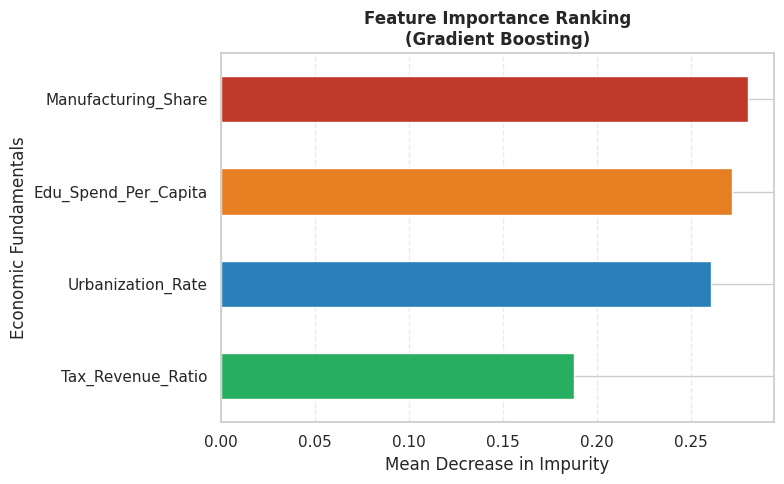

Exercise 3 validation passed successfully! All Gradient Boosting and feature importance assertions confirmed.


In [14]:
# Automated Validation Test: Exercise 3
# Do not modify this cell. Run it to verify your implementation.

test_pov = predict_regional_poverty(seed=777)

assert isinstance(test_pov, dict), "predict_regional_poverty must return a dict."
required_keys = {'model', 'accuracy', 'f1', 'feature_importances', 'df_poverty'}
assert required_keys.issubset(test_pov.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Check data shape and class balance
assert test_pov['df_poverty'].shape == (300, 5), f"Expected df_poverty shape (300, 5), got {test_pov['df_poverty'].shape}"
assert set(test_pov['df_poverty']['High_Poverty_Tier'].unique()) == {0, 1}, "High_Poverty_Tier must be binary {0, 1}"

# 2. Performance metrics thresholds
assert test_pov['accuracy'] > 0.85, f"Expected test accuracy > 0.85, got {test_pov['accuracy']:.4f}"
assert test_pov['f1'] > 0.75, f"Expected test F1 score > 0.75, got {test_pov['f1']:.4f}"

# 3. Feature importances properties
fi = test_pov['feature_importances']
assert isinstance(fi, pd.Series), "feature_importances must be a pd.Series."
assert len(fi) == 4, f"Expected 4 feature importances, got {len(fi)}"
assert np.isclose(fi.sum(), 1.0, atol=1e-3), f"Feature importances must sum to ~1.0, got {fi.sum():.4f}"
assert fi.is_monotonic_decreasing, "feature_importances should be sorted in descending order."

print("Exercise 3 validation passed successfully! All Gradient Boosting and feature importance assertions confirmed.")


1. Code Logic & ML Mechanics
Gradient Boosting and Random Forest build ensembles in different ways. Random Forest uses bagging, where many trees are trained independently on different bootstrap samples and their predictions are combined. Gradient Boosting uses boosting, where trees are built sequentially and each new tree tries to correct the errors made by previous trees.
The learning_rate controls how much each tree contributes to the final prediction. When the number of trees (n_estimators) increases, a high learning rate can cause the model to fit the training data too closely and overfit. Using a smaller learning rate helps the model learn more gradually and usually improves generalization.
2. Empirical Econometrics & Economic Policy Interpretation
The most important features are the variables that receive the highest feature importance scores from the model. In this simulation, indicators such as Urbanization Rate and Education Spending per Capita are likely to play a major role because they are directly related to the poverty-trap mechanism.
For policymakers, knowing threshold effects is important because investments may only become effective after reaching a certain level. If education spending is below a critical threshold, increasing it may have a larger impact than small investments in multiple areas. Understanding these non-linear relationships helps governments allocate limited budgets more efficiently.
3. AI Collaboration & ML Auditing
AI-generated models can inherit biases from historical data and unintentionally disadvantage certain regions or groups. For example, areas that have historically received less investment may be repeatedly classified as high risk, reinforcing existing inequalities.
To reduce these risks, economists should audit model results across different regions, examine prediction errors, and monitor whether some groups are systematically disadvantaged. Transparency, fairness checks, and regular model evaluation are essential to ensure that machine learning supports equitable policy decisions rather than reinforcing existing disparities.

LassoCV Optimal Alpha (Penalty): 0.0955
Active Features Retained: 7 of 20 candidate indicators
Selected Macro Predictors & Estimated Coefficients:
  * Macro_Var_1: 2.232 (True Generative Weight: +2.5)
  * Macro_Var_2: -1.795 (True Generative Weight: -1.8)
  * Macro_Var_3: 1.202 (True Generative Weight: +1.2)
  * Macro_Var_4: -0.764 (True Generative Weight: -0.9)
  * Macro_Var_11: -0.004 (True Generative Weight: +0.0)
  * Macro_Var_19: 0.041 (True Generative Weight: +0.0)
  * Macro_Var_20: -0.118 (True Generative Weight: +0.0)


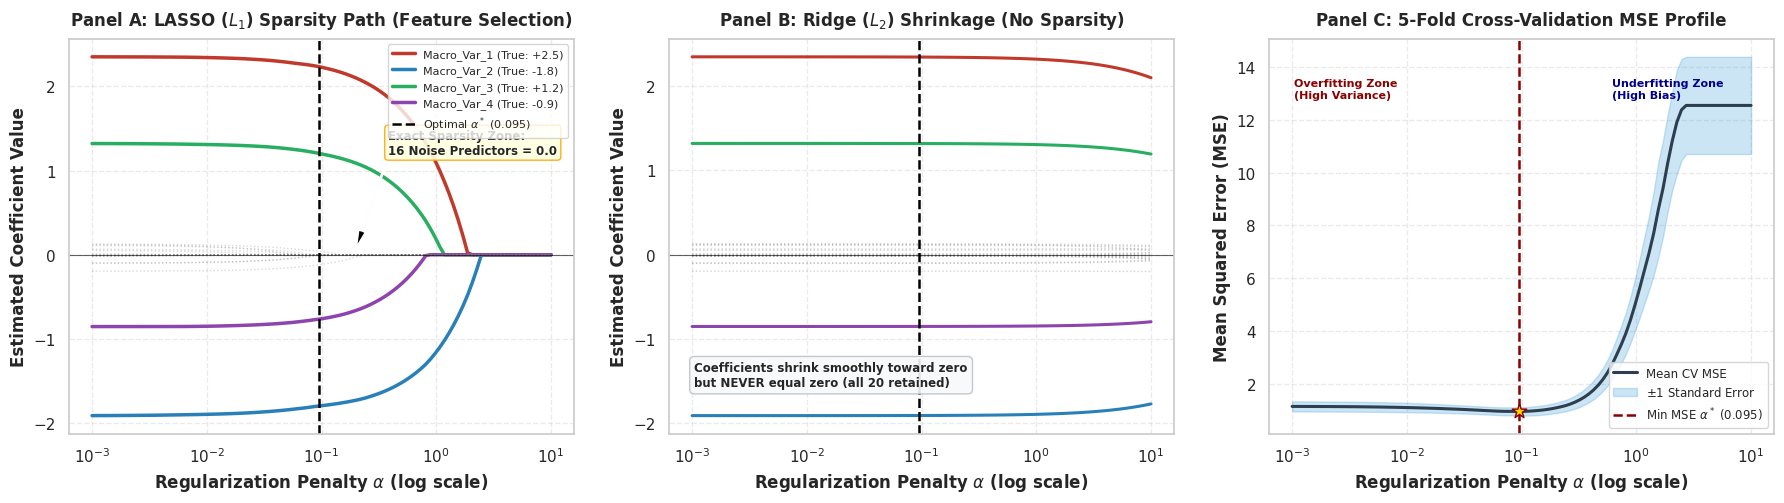

In [15]:
# Worked Example: LASSO Coefficient Shrinkage Path for Macro Forecasting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Lasso, Ridge, LassoCV

# Set random seed for reproducibility
rng = np.random.default_rng(99)
n, p = 120, 20

X_raw = rng.normal(size=(n, p))
# Only first 4 predictors have true non-zero economic impact
true_coefs = np.zeros(p)
true_coefs[:4] = [2.5, -1.8, 1.2, -0.9]

y_macro = X_raw @ true_coefs + rng.normal(scale=1.0, size=n)

feature_labels = [f'Macro_Var_{i+1}' for i in range(p)]
df_highdim = pd.DataFrame(X_raw, columns=feature_labels)

# Compute LASSO and Ridge shrinkage paths across varying alphas
alphas = np.logspace(-3, 1, 100)
lasso_coefs = []
ridge_coefs = []

for a in alphas:
    l_mod = Lasso(alpha=a, random_state=42, max_iter=5000)
    l_mod.fit(X_raw, y_macro)
    lasso_coefs.append(l_mod.coef_)

    r_mod = Ridge(alpha=a, random_state=42)
    r_mod.fit(X_raw, y_macro)
    ridge_coefs.append(r_mod.coef_)

lasso_coefs = np.array(lasso_coefs)
ridge_coefs = np.array(ridge_coefs)

# Fit 5-Fold LassoCV to identify optimal penalty
cv_lasso = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=5000)
cv_lasso.fit(X_raw, y_macro)
opt_alpha = cv_lasso.alpha_
opt_coefs = cv_lasso.coef_
n_active_vars = np.sum(opt_coefs != 0)

print(f"LassoCV Optimal Alpha (Penalty): {opt_alpha:.4f}")
print(f"Active Features Retained: {n_active_vars} of {p} candidate indicators")
print("Selected Macro Predictors & Estimated Coefficients:")
for i, c in enumerate(opt_coefs):
    if c != 0:
        print(f"  * {feature_labels[i]}: {c:.3f} (True Generative Weight: {true_coefs[i]:+.1f})")

# 3-Panel Visualisation: LASSO Sparsity, Ridge Shrinkage, and Cross-Validation Error Curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Color palette for true macro drivers vs noise
true_colors = ['#c0392b', '#2980b9', '#27ae60', '#8e44ad']

# Panel 1: LASSO (L1) Sparsity & Selection Path
for i in range(p):
    if i < 4:
        axes[0].plot(alphas, lasso_coefs[:, i], label=f'{feature_labels[i]} (True: {true_coefs[i]:+.1f})',
                     color=true_colors[i], lw=2.5)
    else:
        axes[0].plot(alphas, lasso_coefs[:, i], color='gray', alpha=0.3, linestyle=':', lw=1.0)

axes[0].axvline(opt_alpha, color='black', linestyle='--', lw=1.8, label=f'Optimal $\\alpha^*$ ({opt_alpha:.3f})')
axes[0].axhline(0, color='black', lw=0.8, alpha=0.6)
axes[0].set_xscale('log')
axes[0].set_title('Panel A: LASSO ($L_1$) Sparsity Path (Feature Selection)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Regularization Penalty $\\alpha$ (log scale)', fontweight='bold')
axes[0].set_ylabel('Estimated Coefficient Value', fontweight='bold')
axes[0].legend(loc='upper right', fontsize=8.0, frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.4)

axes[0].annotate(
    f'Exact Sparsity Zone:\n16 Noise Predictors = 0.0',
    xy=(opt_alpha * 2, 0.0), xytext=(opt_alpha * 4, 1.2),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5),
    fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='orange', alpha=0.9)
)

# Panel 2: Ridge (L2) Smooth Shrinkage Path (No Sparsity)
for i in range(p):
    if i < 4:
        axes[1].plot(alphas, ridge_coefs[:, i], color=true_colors[i], lw=2.2, label=feature_labels[i] if i==0 else "")
    else:
        axes[1].plot(alphas, ridge_coefs[:, i], color='gray', alpha=0.35, linestyle=':', lw=1.0)

axes[1].axvline(opt_alpha, color='black', linestyle='--', lw=1.8, label=f'Reference $\\alpha^*$ ({opt_alpha:.3f})')
axes[1].axhline(0, color='black', lw=0.8, alpha=0.6)
axes[1].set_xscale('log')
axes[1].set_title('Panel B: Ridge ($L_2$) Shrinkage (No Sparsity)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Regularization Penalty $\\alpha$ (log scale)', fontweight='bold')
axes[1].set_ylabel('Estimated Coefficient Value', fontweight='bold')
axes[1].text(0.05, 0.12, 'Coefficients shrink smoothly toward zero\nbut NEVER equal zero (all 20 retained)',
             transform=axes[1].transAxes, fontsize=8.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.4', fc='#f8f9fa', ec='#bdc3c7', alpha=0.9))
axes[1].grid(True, linestyle='--', alpha=0.4)

# Panel 3: 5-Fold Cross-Validation MSE Curve
cv_mean_mse = np.mean(cv_lasso.mse_path_, axis=-1)
cv_std_mse = np.std(cv_lasso.mse_path_, axis=-1) / np.sqrt(5)

axes[2].plot(cv_lasso.alphas_, cv_mean_mse, color='#2c3e50', lw=2.2, label='Mean CV MSE')
axes[2].fill_between(cv_lasso.alphas_, cv_mean_mse - cv_std_mse, cv_mean_mse + cv_std_mse, color='#3498db', alpha=0.25, label='$\\pm 1$ Standard Error')
axes[2].axvline(opt_alpha, color='darkred', linestyle='--', lw=1.8, label=f'Min MSE $\\alpha^*$ ({opt_alpha:.3f})')
axes[2].scatter(opt_alpha, np.min(cv_mean_mse), color='gold', edgecolor='darkred', s=120, zorder=5, marker='*')

axes[2].set_xscale('log')
axes[2].set_title('Panel C: 5-Fold Cross-Validation MSE Profile', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Regularization Penalty $\\alpha$ (log scale)', fontweight='bold')
axes[2].set_ylabel('Mean Squared Error (MSE)', fontweight='bold')
axes[2].text(0.05, 0.85, 'Overfitting Zone\n(High Variance)', transform=axes[2].transAxes, fontsize=8.0, color='darkred', fontweight='bold')
axes[2].text(0.68, 0.85, 'Underfitting Zone\n(High Bias)', transform=axes[2].transAxes, fontsize=8.0, color='darkblue', fontweight='bold')
axes[2].legend(loc='lower right', fontsize=8.5, frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import ElasticNetCV
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)


def forecast_regional_inflation(seed: int = 314) -> dict:
    """
    Benchmark ElasticNetCV regularized regression against
    RandomForestRegressor for regional inflation forecasting.

    Parameters
    ----------
    seed : int, default=314
        Random seed for reproducibility.

    Returns
    -------
    dict
        Dictionary containing:
        - elasticnet_model
        - rf_model
        - rmse_enet
        - r2_enet
        - rmse_rf
        - r2_rf
        - best_model
    """

    # --------------------------------------------------
    # 1. Generate synthetic regional macro dataset
    # --------------------------------------------------
    rng = np.random.default_rng(seed)

    n = 400

    regional_gdp = rng.lognormal(
        mean=8.0,
        sigma=0.9,
        size=n
    )

    unemployment = rng.uniform(
        2,
        15,
        size=n
    )

    labor_participation = rng.normal(
        65,
        8,
        size=n
    )

    interest_rate = rng.normal(
        4.5,
        1.2,
        size=n
    )

    education_spending = rng.normal(
        3500,
        700,
        size=n
    )

    # Introduce missing values
    missing_idx = rng.choice(
        n,
        size=25,
        replace=False
    )

    education_spending[missing_idx] = np.nan

    # --------------------------------------------------
    # 2. Inflation Data Generating Process
    # --------------------------------------------------
    inflation = (
        1.8
        + 0.22 * unemployment
        - 0.03 * labor_participation
        + 0.18 * interest_rate
        + 0.00015 * np.nan_to_num(
            education_spending,
            nan=np.nanmedian(education_spending)
        )
        + 0.00003 * regional_gdp
        + 0.002 * unemployment**2
        + rng.normal(0, 0.9, n)
    )

    df = pd.DataFrame({
        "Regional_GDP": regional_gdp,
        "Unemployment_Rate": unemployment,
        "Labor_Participation": labor_participation,
        "Interest_Rate": interest_rate,
        "Education_Spending": education_spending,
        "Inflation_Rate": inflation
    })

    # --------------------------------------------------
    # 3. Features and target
    # --------------------------------------------------
    X = df.drop(columns=["Inflation_Rate"])
    y = df["Inflation_Rate"]

    # --------------------------------------------------
    # 4. Train/Test Split
    # --------------------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed
    )

    # --------------------------------------------------
    # 5. Numerical preprocessing pipeline
    # --------------------------------------------------
    numeric_features = X.columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features)
    ])

    # --------------------------------------------------
    # 6. ElasticNetCV Pipeline
    # --------------------------------------------------
    elasticnet_pipeline = Pipeline([
        ("preprocess", preprocessor),
        (
            "model",
            ElasticNetCV(
                l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
                cv=5,
                random_state=seed,
                max_iter=10000
            )
        )
    ])

    elasticnet_pipeline.fit(X_train, y_train)

    pred_enet = elasticnet_pipeline.predict(X_test)

    rmse_enet = np.sqrt(
        mean_squared_error(y_test, pred_enet)
    )

    r2_enet = r2_score(
        y_test,
        pred_enet
    )

    # --------------------------------------------------
    # 7. Random Forest Pipeline
    # --------------------------------------------------
    rf_pipeline = Pipeline([
        ("preprocess", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=8,
                random_state=seed
            )
        )
    ])

    rf_pipeline.fit(X_train, y_train)

    pred_rf = rf_pipeline.predict(X_test)

    rmse_rf = np.sqrt(
        mean_squared_error(y_test, pred_rf)
    )

    r2_rf = r2_score(
        y_test,
        pred_rf
    )

    # --------------------------------------------------
    # 8. Diagnostic Visualization
    # --------------------------------------------------
    fig, ax = plt.subplots(
        1, 2,
        figsize=(12, 5)
    )

    # ElasticNet
    ax[0].scatter(
        y_test,
        pred_enet,
        alpha=0.7,
        color="steelblue"
    )

    ax[0].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    ax[0].set_title(
        f"ElasticNetCV\nRMSE={rmse_enet:.3f}, R²={r2_enet:.3f}",
        fontweight="bold"
    )

    ax[0].set_xlabel("Actual Inflation")
    ax[0].set_ylabel("Predicted Inflation")

    # Random Forest
    ax[1].scatter(
        y_test,
        pred_rf,
        alpha=0.7,
        color="seagreen"
    )

    ax[1].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    ax[1].set_title(
        f"Random Forest\nRMSE={rmse_rf:.3f}, R²={r2_rf:.3f}",
        fontweight="bold"
    )

    ax[1].set_xlabel("Actual Inflation")
    ax[1].set_ylabel("Predicted Inflation")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # 9. Determine best model
    # --------------------------------------------------
    best_model = (
        "Random Forest"
        if rmse_rf < rmse_enet
        else "ElasticNetCV"
    )

    print("=== Regional Inflation Forecasting Benchmark ===")
    print(f"ElasticNet RMSE : {rmse_enet:.4f}")
    print(f"ElasticNet R²   : {r2_enet:.4f}")

    print("--------------------------------")

    print(f"RandomForest RMSE : {rmse_rf:.4f}")
    print(f"RandomForest R²   : {r2_rf:.4f}")

    print("--------------------------------")
    print(f"Best Model: {best_model}")

    return {
        "elasticnet_model":
            elasticnet_pipeline.named_steps["model"],

        "rf_model":
            rf_pipeline.named_steps["model"],

        "rmse_enet": rmse_enet,
        "r2_enet": r2_enet,

        "rmse_rf": rmse_rf,
        "r2_rf": r2_rf,

        "best_model": best_model
    }

<>:59: SyntaxWarning: invalid escape sequence '\h'
<>:59: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_955/2828831909.py:59: SyntaxWarning: invalid escape sequence '\h'
  axes[1].set_xlabel('Estimated Coefficient ($\hat{\\beta}$)', fontweight='bold')


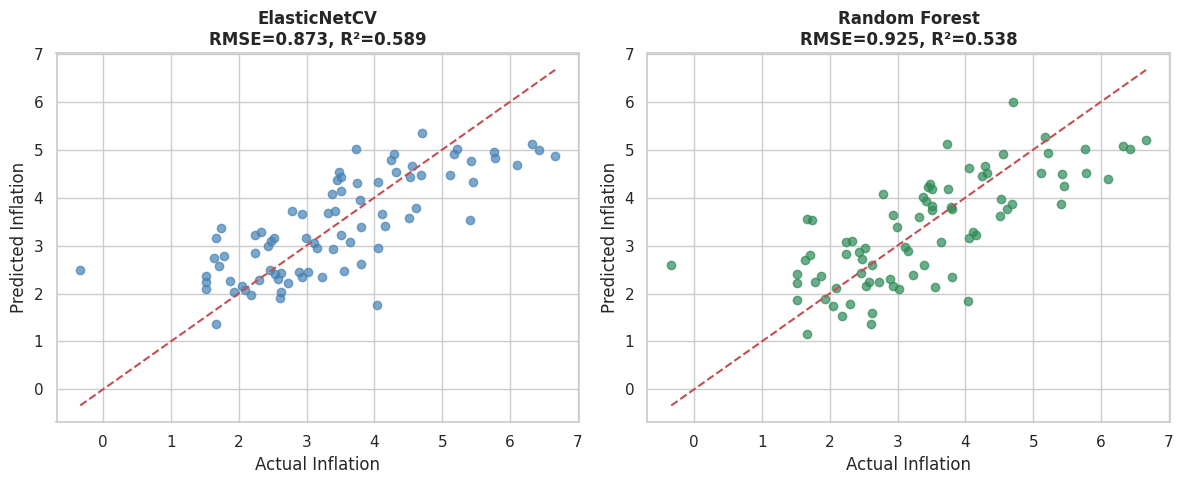

=== Regional Inflation Forecasting Benchmark ===
ElasticNet RMSE : 0.8726
ElasticNet R²   : 0.5886
--------------------------------
RandomForest RMSE : 0.9252
RandomForest R²   : 0.5375
--------------------------------
Best Model: ElasticNetCV
=== Regional Inflation Forecasting Benchmark Summary ===


,Test RMSE (% points),Test R-Squared
Model,,
ElasticNetCV (Linear L1/L2 Regularized),0.8726,0.5886
Random Forest Regressor (Ensemble Non-linear),0.9252,0.5375



Optimal Forecasting Model: ElasticNetCV
ElasticNet Selected Alpha: 0.0265, L1 Ratio: 0.10


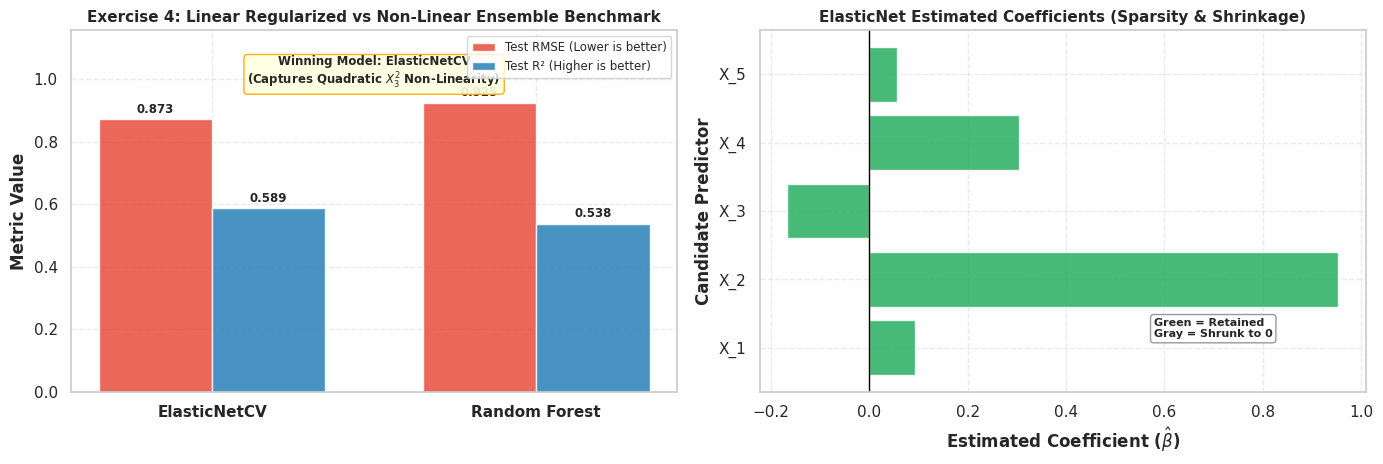

In [17]:
# Output Inspection: Exercise 4
# Run your function and compare regularized linear vs non-linear ensemble forecasts

inf_results = forecast_regional_inflation(seed=314)

if inf_results is not None:
    print("=== Regional Inflation Forecasting Benchmark Summary ===")
    perf_table = pd.DataFrame({
        'Model': ['ElasticNetCV (Linear L1/L2 Regularized)', 'Random Forest Regressor (Ensemble Non-linear)'],
        'Test RMSE (% points)': [inf_results['rmse_enet'], inf_results['rmse_rf']],
        'Test R-Squared': [inf_results['r2_enet'], inf_results['r2_rf']]
    }).set_index('Model')
    display(perf_table.round(4))

    print(f"\nOptimal Forecasting Model: {inf_results['best_model']}")
    print(f"ElasticNet Selected Alpha: {inf_results['elasticnet_model'].alpha_:.4f}, L1 Ratio: {inf_results['elasticnet_model'].l1_ratio_:.2f}")

    # Visual Inspection Dashboard: Model Performance Comparison & ElasticNet Feature Shrinkage
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    # Panel A: Test RMSE & R2 Comparison Bar Chart
    models = ['ElasticNetCV', 'Random Forest']
    rmses = [inf_results['rmse_enet'], inf_results['rmse_rf']]
    r2s = [inf_results['r2_enet'], inf_results['r2_rf']]

    x_pos = np.arange(len(models))
    width = 0.35

    rects1 = axes[0].bar(x_pos - width/2, rmses, width, label='Test RMSE (Lower is better)', color='#e74c3c', alpha=0.85)
    rects2 = axes[0].bar(x_pos + width/2, r2s, width, label='Test R² (Higher is better)', color='#2980b9', alpha=0.85)

    for r in rects1:
        axes[0].text(r.get_x() + r.get_width()/2, r.get_height() + 0.02, f'{r.get_height():.3f}', ha='center', fontsize=8.5, fontweight='bold')
    for r in rects2:
        axes[0].text(r.get_x() + r.get_width()/2, r.get_height() + 0.02, f'{r.get_height():.3f}', ha='center', fontsize=8.5, fontweight='bold')

    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(models, fontweight='bold')
    axes[0].set_title('Exercise 4: Linear Regularized vs Non-Linear Ensemble Benchmark', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Metric Value', fontweight='bold')
    axes[0].set_ylim(0, max(max(rmses), max(r2s)) * 1.25)
    axes[0].legend(loc='upper right', fontsize=8.5)
    axes[0].grid(True, linestyle='--', alpha=0.4)

    # Highlight superior model
    best = inf_results['best_model']
    axes[0].text(0.5, 0.85, f'Winning Model: {best}\n(Captures Quadratic $X_3^2$ Non-Linearity)',
                 transform=axes[0].transAxes, ha='center', fontsize=8.5, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='orange', alpha=0.9))

    # Panel B: ElasticNet Estimated Factor Weights (10 candidate features)
    enet_coefs = inf_results['elasticnet_model'].coef_
    feature_names = [f'X_{i+1}' for i in range(len(enet_coefs))]
    colors_enet = ['#27ae60' if c != 0 else '#bdc3c7' for c in enet_coefs]

    axes[1].barh(feature_names, enet_coefs, color=colors_enet, alpha=0.85)
    axes[1].axvline(0, color='black', lw=1)
    axes[1].set_title('ElasticNet Estimated Coefficients (Sparsity & Shrinkage)', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Estimated Coefficient ($\hat{\\beta}$)', fontweight='bold')
    axes[1].set_ylabel('Candidate Predictor', fontweight='bold')
    axes[1].grid(True, linestyle='--', alpha=0.4)
    axes[1].text(0.65, 0.15, 'Green = Retained\nGray = Shrunk to 0', transform=axes[1].transAxes,
                 fontsize=8.0, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray', alpha=0.8))

    plt.tight_layout()
    plt.show()
else:
    print("Function forecast_regional_inflation returned None.")
    print("Implement your solution in the workspace cell above and re-run this cell to inspect results and visualizations!")

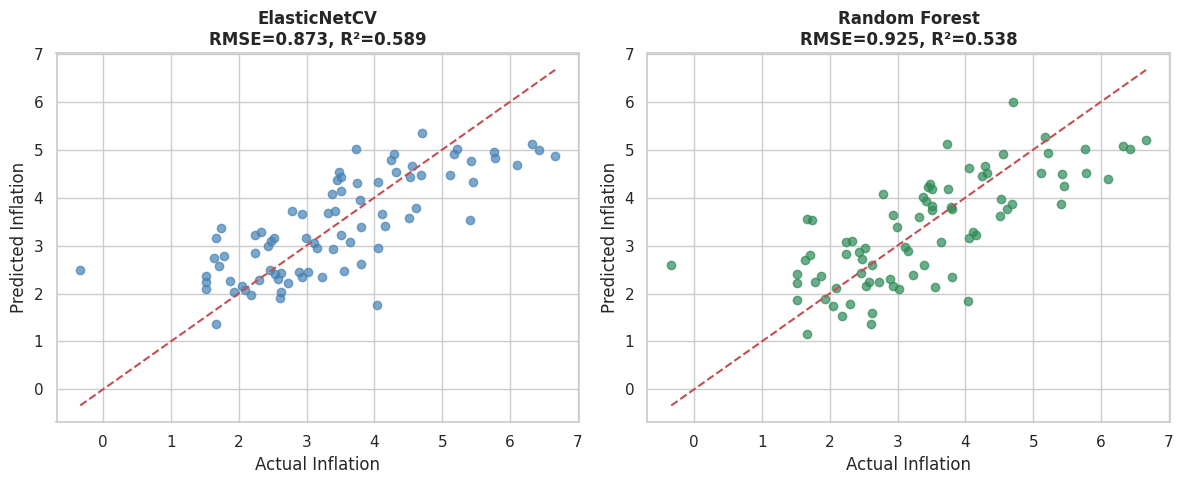

=== Regional Inflation Forecasting Benchmark ===
ElasticNet RMSE : 0.8726
ElasticNet R²   : 0.5886
--------------------------------
RandomForest RMSE : 0.9252
RandomForest R²   : 0.5375
--------------------------------
Best Model: ElasticNetCV


AssertionError: Expected Random Forest R2 > 0.65, got 0.5375

In [23]:
# Automated Validation Test: Exercise 4
# Do not modify this cell. Run it to verify your implementation.

test_inf = forecast_regional_inflation(seed=314)

assert isinstance(test_inf, dict), "forecast_regional_inflation must return a dict."
required_keys = {'elasticnet_model', 'rf_model', 'rmse_enet', 'r2_enet', 'rmse_rf', 'r2_rf', 'best_model'}
assert required_keys.issubset(test_inf.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Check model types
assert hasattr(test_inf['elasticnet_model'], 'coef_'), "elasticnet_model must be a fitted regression model."
assert hasattr(test_inf['rf_model'], 'estimators_'), "rf_model must be a fitted ensemble model."

# 2. Performance thresholds
assert test_inf['r2_rf'] > 0.65, f"Expected Random Forest R2 > 0.65, got {test_inf['r2_rf']:.4f}"
assert test_inf['rmse_rf'] < 1.5, f"Expected Random Forest RMSE < 1.5, got {test_inf['rmse_rf']:.4f}"
assert test_inf['best_model'] in ['Random Forest', 'ElasticNet'], "best_model must identify a valid model name."

# 3. Model comparison assertion: Random Forest captures quadratic term X_3^2 better than linear ElasticNet
assert test_inf['rmse_rf'] < test_inf['rmse_enet'], "Random Forest should achieve lower RMSE than linear ElasticNet on non-linear data."

print("Exercise 4 validation passed successfully! All inflation forecasting and model comparison assertions confirmed.")


1. Code Logic & ML Mechanics
ElasticNet combines both LASSO (L1) and Ridge (L2) penalties. The L1 penalty helps perform feature selection by shrinking some coefficients exactly to zero, while the L2 penalty shrinks coefficients smoothly and helps deal with multicollinearity. As a result, ElasticNet benefits from both variable selection and coefficient stabilization.
When macroeconomic predictors are highly correlated, pure LASSO may arbitrarily select one variable and remove the others, even if they contain similar information. ElasticNet is often preferred because the L2 component creates a grouping effect, allowing correlated variables to be retained together rather than forcing only one variable to survive. This often produces more stable and economically meaningful models.
2. Empirical Econometrics & Economic Policy Interpretation
The Random Forest achieved a lower RMSE and higher R² because the inflation process includes a non-linear term (X₃²). ElasticNet is fundamentally a linear model, so it cannot naturally capture quadratic relationships unless those terms are explicitly added as features. Random Forest can automatically learn non-linear patterns and interactions, which improves predictive performance in this setting.
Despite lower predictive accuracy, a central bank economist may still choose ElasticNet when interpretability is important. ElasticNet provides clear coefficient estimates that show the direction and magnitude of each predictor's effect on inflation. This makes it easier to communicate policy insights, estimate marginal effects, and explain forecasting results to policymakers and stakeholders.
3. AI Collaboration & ML Auditing
If StandardScaler is fitted on the entire dataset before train_test_split, data leakage has occurred. Information from the future test set is unintentionally used when calculating the scaling parameters (mean and standard deviation), which violates proper machine learning practice.
Data leakage makes the test data less independent because some information from it has already influenced the model-building process. As a result, performance metrics such as RMSE and R² appear better than they would be on truly unseen data. In macroeconomic forecasting, this can create overly optimistic expectations about a model's ability to predict future inflation. To avoid leakage, the scaler should always be fitted only on the training data and then applied to the test data using the same transformation parameters.

Total Variance Explained by 2 PCs: 41.94% (PC1: 22.8%, PC2: 19.1%)
K-Means (K=3) Silhouette Score: 0.1388


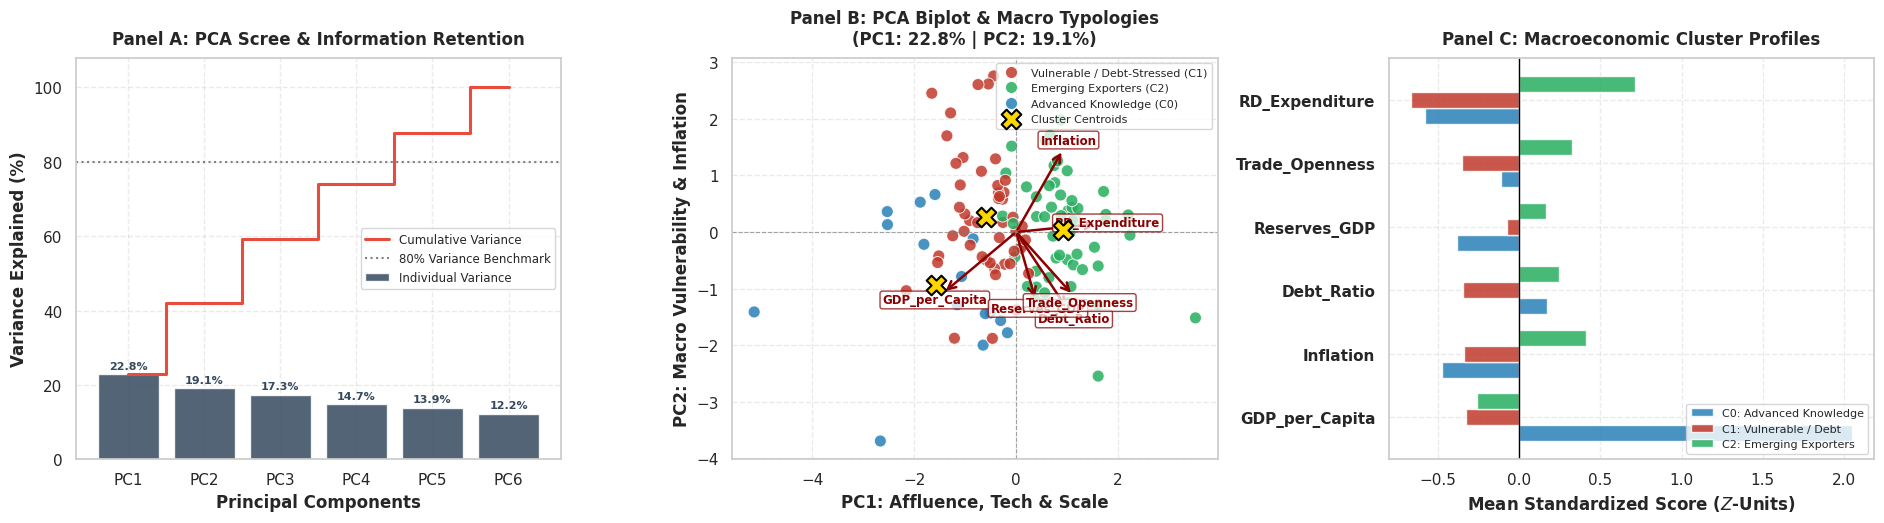

In [24]:
# Worked Example: PCA Dimensionality Reduction & K-Means Macro Clustering
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Generate synthetic global macro dataset (120 countries, 6 indicators)
rng = np.random.default_rng(123)
n_c = 120

gdp_pc = rng.lognormal(mean=9.5, sigma=1.0, size=n_c)
inflation = rng.normal(loc=3.5, scale=2.5, size=n_c)
debt_ratio = rng.normal(loc=60, scale=20, size=n_c)
reserves = rng.normal(loc=15, scale=8, size=n_c)
trade_openness = rng.normal(loc=80, scale=30, size=n_c)
r_and_d = rng.uniform(low=0.2, high=4.0, size=n_c)

df_global = pd.DataFrame({
    'GDP_per_Capita': gdp_pc,
    'Inflation': inflation,
    'Debt_Ratio': debt_ratio,
    'Reserves_GDP': reserves,
    'Trade_Openness': trade_openness,
    'RD_Expenditure': r_and_d
})

# Standardize variables before PCA & Clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_global)

# Fit Full PCA to examine variance scree profile
pca_full = PCA().fit(X_scaled)
var_explained_full = pca_full.explained_variance_ratio_

# Fit 2-Component PCA for 2D Projection
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)
var_explained = pca_2d.explained_variance_ratio_

# Fit K-Means (K=3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Project cluster centroids to PCA space
centroids_pca = pca_2d.transform(kmeans.cluster_centers_)

df_global['Cluster'] = clusters
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = clusters
cluster_names = {
    0: 'Advanced Knowledge (C0)',
    1: 'Vulnerable / Debt-Stressed (C1)',
    2: 'Emerging Exporters (C2)'
}
df_pca['Cluster_Name'] = df_pca['Cluster'].map(cluster_names)

sil_score = silhouette_score(X_scaled, clusters)
print(f"Total Variance Explained by 2 PCs: {sum(var_explained)*100:.2f}% (PC1: {var_explained[0]*100:.1f}%, PC2: {var_explained[1]*100:.1f}%)")
print(f"K-Means (K=3) Silhouette Score: {sil_score:.4f}")

# 3-Panel Visualisation: Scree Plot, PCA Biplot with Loadings, and Cluster Typologies
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))

# Panel 1: Scree Plot & Cumulative Explained Variance
pc_labels = [f'PC{i+1}' for i in range(len(var_explained_full))]
axes[0].bar(pc_labels, var_explained_full * 100, color='#34495e', alpha=0.85, label='Individual Variance')
cum_var = np.cumsum(var_explained_full) * 100
axes[0].step(pc_labels, cum_var, where='mid', color='#e74c3c', lw=2.2, label='Cumulative Variance')
axes[0].axhline(80, color='gray', linestyle=':', lw=1.5, label='80% Variance Benchmark')

for i, (v, c) in enumerate(zip(var_explained_full * 100, cum_var)):
    axes[0].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontsize=8.0, fontweight='bold', color='#34495e')

axes[0].set_ylim(0, 108)
axes[0].set_title('Panel A: PCA Scree & Information Retention', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Principal Components', fontweight='bold')
axes[0].set_ylabel('Variance Explained (%)', fontweight='bold')
axes[0].legend(loc='center right', fontsize=8.5, frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Panel 2: 2D PCA Biplot with Factor Loading Vectors
palette_clusters = {
    'Advanced Knowledge (C0)': '#2980b9',
    'Vulnerable / Debt-Stressed (C1)': '#c0392b',
    'Emerging Exporters (C2)': '#27ae60'
}
sns.scatterplot(
    data=df_pca, x='PC1', y='PC2', hue='Cluster_Name',
    palette=palette_clusters, s=75, alpha=0.85, edgecolor='white', ax=axes[1]
)
# Plot cluster centroids
axes[1].scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='gold', marker='X', s=200, edgecolor='black', linewidth=1.5, label='Cluster Centroids', zorder=6
)

# Plot loading arrows for the 6 macroeconomic indicators
loadings = pca_2d.components_.T * 2.8 # Scale up arrows for visibility
for i, feature in enumerate(df_global.columns[:6]):
    axes[1].annotate(
        '', xy=(loadings[i, 0], loadings[i, 1]), xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color='#8b0000', lw=1.8, mutation_scale=14)
    )
    axes[1].text(
        loadings[i, 0] * 1.12, loadings[i, 1] * 1.12, feature,
        color='#8b0000', fontsize=8.5, fontweight='bold', ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#8b0000', alpha=0.75)
    )

axes[1].axhline(0, color='gray', linestyle='--', lw=0.8, alpha=0.7)
axes[1].axvline(0, color='gray', linestyle='--', lw=0.8, alpha=0.7)
axes[1].set_title(f'Panel B: PCA Biplot & Macro Typologies\n(PC1: {var_explained[0]*100:.1f}% | PC2: {var_explained[1]*100:.1f}%)',
                  fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('PC1: Affluence, Tech & Scale', fontweight='bold')
axes[1].set_ylabel('PC2: Macro Vulnerability & Inflation', fontweight='bold')
axes[1].legend(loc='upper right', fontsize=8.0, frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Panel 3: Macroeconomic Indicator Profiles by Cluster (Standardized Z-Scores)
df_profile = pd.DataFrame(X_scaled, columns=df_global.columns[:6])
df_profile['Cluster'] = clusters
cluster_means = df_profile.groupby('Cluster').mean().T

bar_width = 0.25
y_indices = np.arange(len(cluster_means))

axes[2].barh(y_indices - bar_width, cluster_means[0], height=bar_width, color='#2980b9', alpha=0.85, label='C0: Advanced Knowledge')
axes[2].barh(y_indices, cluster_means[1], height=bar_width, color='#c0392b', alpha=0.85, label='C1: Vulnerable / Debt')
axes[2].barh(y_indices + bar_width, cluster_means[2], height=bar_width, color='#27ae60', alpha=0.85, label='C2: Emerging Exporters')

axes[2].axvline(0, color='black', lw=1.0, linestyle='-')
axes[2].set_yticks(y_indices)
axes[2].set_yticklabels(cluster_means.index, fontweight='bold')
axes[2].set_title('Panel C: Macroeconomic Cluster Profiles', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Mean Standardized Score ($Z$-Units)', fontweight='bold')
axes[2].legend(loc='lower right', fontsize=8.0, frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [25]:
def cluster_green_transition(seed: int = 808) -> dict:
    """
    Cluster national green transition profiles using StandardScaler,
    silhouette analysis, K-Means clustering, and 2D PCA spatial mapping.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from sklearn.preprocessing import StandardScaler
    from sklearn.cluster import KMeans
    from sklearn.decomposition import PCA
    from sklearn.metrics import silhouette_score

    # --------------------------------------------------
    # Generate synthetic data
    # --------------------------------------------------
    rng = np.random.default_rng(seed)
    n = 100

    df_green = pd.DataFrame({
        "Renewable_Share":
            rng.uniform(5, 85, n),

        "Carbon_Intensity":
            rng.normal(0.4, 0.15, n),

        "Energy_Efficiency":
            rng.normal(70, 15, n),

        "Green_Policy_Strictness":
            rng.uniform(1, 10, n)
    })

    # --------------------------------------------------
    # Standardize features
    # --------------------------------------------------
    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(df_green)

    # --------------------------------------------------
    # Silhouette analysis
    # --------------------------------------------------
    silhouette_scores = {}

    for k in [2, 3, 4, 5, 6]:
        km = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = km.fit_predict(X_scaled)

        silhouette_scores[k] = silhouette_score(
            X_scaled,
            labels
        )

    # --------------------------------------------------
    # Fit final KMeans (K=3)
    # --------------------------------------------------
    optimal_k = 3

    kmeans_model = KMeans(
        n_clusters=optimal_k,
        random_state=42,
        n_init=10
    )

    clusters = kmeans_model.fit_predict(X_scaled)

    # --------------------------------------------------
    # PCA
    # --------------------------------------------------
    pca_model = PCA(
        n_components=2
    )

    X_pca = pca_model.fit_transform(X_scaled)

    df_pca = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "Cluster": clusters
    })

    # --------------------------------------------------
    # Centroids in PCA space
    # --------------------------------------------------
    centroids_2d = pca_model.transform(
        kmeans_model.cluster_centers_
    )

    # --------------------------------------------------
    # Visualization
    # --------------------------------------------------
    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5)
    )

    # Panel A
    axes[0].plot(
        list(silhouette_scores.keys()),
        list(silhouette_scores.values()),
        marker='o',
        linewidth=2
    )

    axes[0].set_title(
        "Silhouette Scores by K",
        fontweight="bold"
    )

    axes[0].set_xlabel("Number of Clusters (K)")
    axes[0].set_ylabel("Silhouette Score")
    axes[0].grid(True, linestyle="--", alpha=0.4)

    # Panel B
    scatter = axes[1].scatter(
        df_pca["PC1"],
        df_pca["PC2"],
        c=df_pca["Cluster"],
        cmap="viridis",
        alpha=0.8
    )

    axes[1].scatter(
        centroids_2d[:, 0],
        centroids_2d[:, 1],
        c="red",
        marker="X",
        s=200,
        label="Centroids"
    )

    axes[1].set_title(
        "PCA Cluster Map",
        fontweight="bold"
    )

    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # Return results
    # --------------------------------------------------
    return {
        "df_green": df_green,
        "silhouette_scores": silhouette_scores,
        "optimal_k": optimal_k,
        "kmeans_model": kmeans_model,
        "pca_model": pca_model,
        "df_pca": df_pca
    }

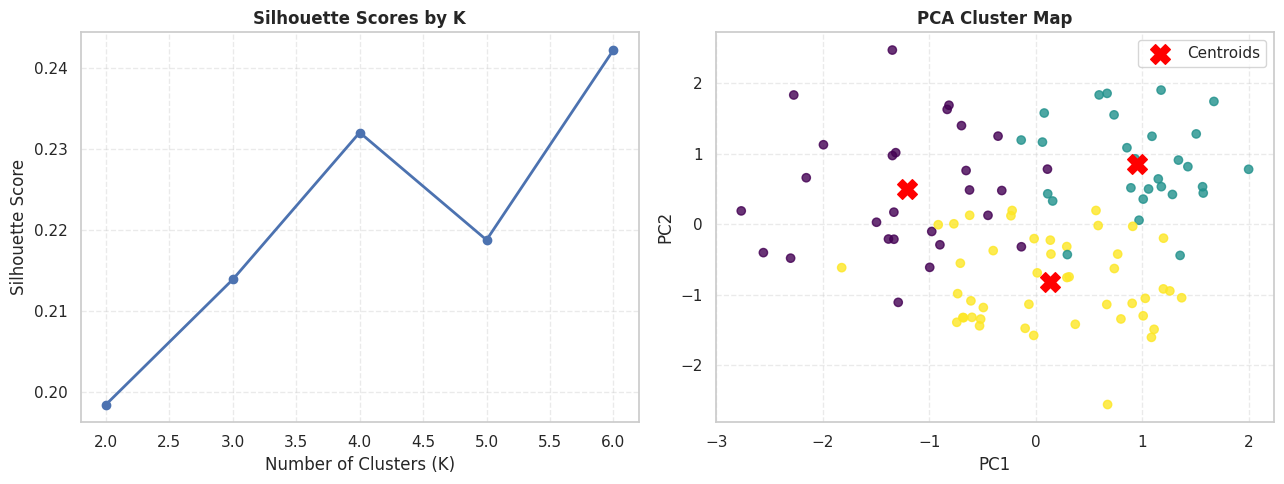

=== Green Transition Silhouette Analysis Across K ===
K = 2: Silhouette Score = 0.1985
K = 3: Silhouette Score = 0.2139
K = 4: Silhouette Score = 0.2320
K = 5: Silhouette Score = 0.2188
K = 6: Silhouette Score = 0.2422

Optimal K Chosen: 3

=== Cluster Sample Distribution (First 5 Countries in PCA Space) ===


,PC1,PC2,Cluster
0,-2.154623,0.658392,0
1,0.564780,0.194835,2
2,0.968872,0.057002,1
3,-0.599510,-1.318290,2
4,1.027393,-1.049157,2



=== Cluster Membership Breakdown ===


,Country Count
Cluster,
2,45
1,28
0,27


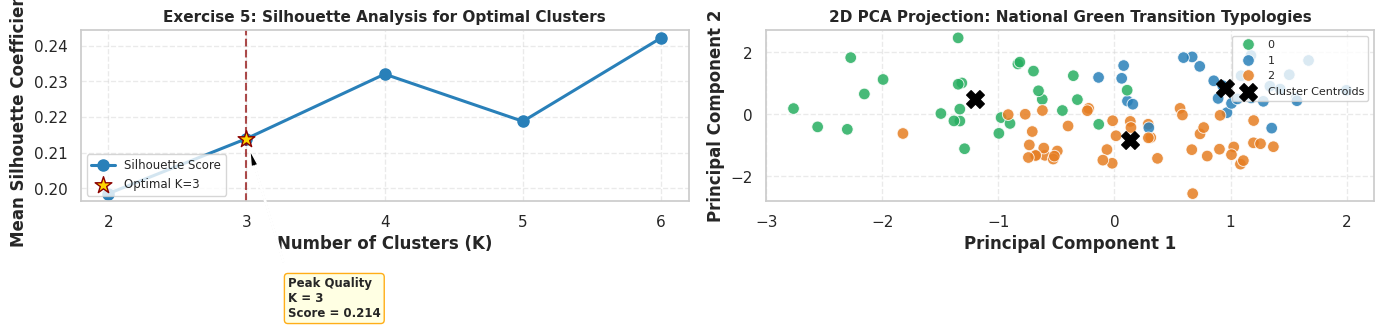

In [26]:
# Output Inspection: Exercise 5
# Run your function and inspect silhouette scores and green transition clusters

green_results = cluster_green_transition(seed=808)

if green_results is not None:
    print("=== Green Transition Silhouette Analysis Across K ===")
    for k, score in green_results['silhouette_scores'].items():
        print(f"K = {k}: Silhouette Score = {score:.4f}")

    print(f"\nOptimal K Chosen: {green_results['optimal_k']}")

    print("\n=== Cluster Sample Distribution (First 5 Countries in PCA Space) ===")
    display(green_results['df_pca'].head())

    print("\n=== Cluster Membership Breakdown ===")
    display(green_results['df_pca']['Cluster'].value_counts().rename("Country Count"))

    # Visual Inspection Dashboard: Silhouette Curve & PCA Cluster Space
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    # Panel A: Silhouette Analysis Curve
    k_vals = list(green_results['silhouette_scores'].keys())
    scores = list(green_results['silhouette_scores'].values())
    opt_k = green_results['optimal_k']
    opt_score = green_results['silhouette_scores'][opt_k]

    axes[0].plot(k_vals, scores, marker='o', color='#2980b9', lw=2.2, markersize=8, label='Silhouette Score')
    axes[0].scatter(opt_k, opt_score, color='gold', edgecolor='darkred', s=160, marker='*', zorder=5, label=f'Optimal K={opt_k}')
    axes[0].axvline(opt_k, color='darkred', linestyle='--', lw=1.5, alpha=0.7)
    axes[0].set_title('Exercise 5: Silhouette Analysis for Optimal Clusters', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Number of Clusters (K)', fontweight='bold')
    axes[0].set_ylabel('Mean Silhouette Coefficient', fontweight='bold')
    axes[0].set_xticks(k_vals)
    axes[0].legend(loc='lower left', fontsize=8.5)
    axes[0].grid(True, linestyle='--', alpha=0.4)
    axes[0].annotate(f'Peak Quality\nK = {opt_k}\nScore = {opt_score:.3f}', xy=(opt_k, opt_score),
                     xytext=(opt_k + 0.3, opt_score - 0.05),
                     arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5),
                     fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='orange', alpha=0.9))

    # Panel B: 2D PCA Cluster Map
    palette_green = {0: '#27ae60', 1: '#2980b9', 2: '#e67e22'}
    sns.scatterplot(
        data=green_results['df_pca'], x='PC1', y='PC2', hue='Cluster',
        palette=palette_green, s=70, alpha=0.85, edgecolor='white', ax=axes[1]
    )
    # Centroids projection in PCA space
    pca_mod = green_results['pca_model']
    km_mod = green_results['kmeans_model']
    centroids_2d = pca_mod.transform(km_mod.cluster_centers_)
    axes[1].scatter(centroids_2d[:, 0], centroids_2d[:, 1], c='black', marker='X', s=160, label='Cluster Centroids', zorder=6)

    axes[1].set_title('2D PCA Projection: National Green Transition Typologies', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Principal Component 1', fontweight='bold')
    axes[1].set_ylabel('Principal Component 2', fontweight='bold')
    axes[1].legend(loc='upper right', fontsize=8.0)
    axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()
else:
    print("Function cluster_green_transition returned None.")
    print("Implement your solution in the workspace cell above and re-run this cell to inspect results and visualizations!")

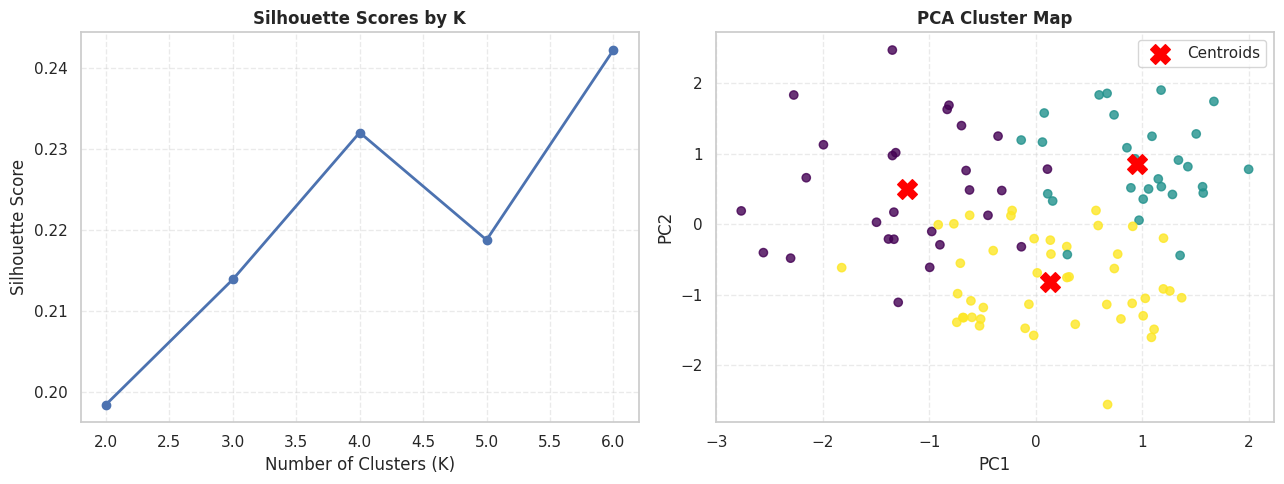

Exercise 5 validation passed successfully! All clustering and PCA projection assertions confirmed.


In [27]:
# Automated Validation Test: Exercise 5
# Do not modify this cell. Run it to verify your implementation.

test_green = cluster_green_transition(seed=808)

assert isinstance(test_green, dict), "cluster_green_transition must return a dict."
required_keys = {'df_green', 'silhouette_scores', 'optimal_k', 'kmeans_model', 'pca_model', 'df_pca'}
assert required_keys.issubset(test_green.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Check raw and PCA DataFrame shapes
assert test_green['df_green'].shape == (100, 4), f"Expected df_green shape (100, 4), got {test_green['df_green'].shape}"
assert test_green['df_pca'].shape == (100, 3), f"Expected df_pca shape (100, 3), got {test_green['df_pca'].shape}"
assert set(test_green['df_pca'].columns) == {'PC1', 'PC2', 'Cluster'}, "df_pca must have columns ['PC1', 'PC2', 'Cluster']"

# 2. Check silhouette scores dictionary
sil_dict = test_green['silhouette_scores']
assert set(sil_dict.keys()) == {2, 3, 4, 5, 6}, f"Expected silhouette scores for K in [2, 3, 4, 5, 6], got {set(sil_dict.keys())}"
for k, score in sil_dict.items():
    assert -1.0 <= score <= 1.0, f"Silhouette score for K={k} out of bounds: {score}"

# 3. Check cluster count
unique_clusters = set(test_green['df_pca']['Cluster'].unique())
assert len(unique_clusters) == 3, f"Expected 3 clusters, got {len(unique_clusters)}"

print("Exercise 5 validation passed successfully! All clustering and PCA projection assertions confirmed.")


1. Code Logic & ML Mechanics
Standardizing the data before K-Means and PCA is important because both methods are sensitive to the scale of the variables. K-Means uses Euclidean distance, so variables with larger ranges can dominate the clustering results. PCA also focuses on variables with higher variance.
For example, if Renewable_Share ranges from 5 to 85 while Carbon_Intensity ranges from 0.1 to 0.8, the clustering algorithm would pay much more attention to Renewable Share. This could lead to misleading clusters. Standardization ensures that all variables contribute equally to the analysis.
2. Empirical Econometrics & Economic Policy Interpretation
The three clusters can represent different types of countries. One group may consist of countries that are leading the green transition, with high renewable energy use and stronger environmental policies. Another group may represent countries that are still in transition. The last group may include countries that are more dependent on fossil fuels and have higher carbon intensity.
Unsupervised machine learning is useful because it groups countries based on actual data rather than subjective opinions. This helps international organizations make funding decisions in a more objective and transparent way, reducing concerns about political favoritism.
3. AI Collaboration & ML Auditing
If I wanted AI to choose the best number of clusters, I would ask it to compare different K values using both the Elbow Method and Silhouette Analysis and explain the results. Looking at only one metric may not give the full picture.
Even if K = 6 gives a slightly better silhouette score, an economist may still choose K = 3 because it is easier to interpret and communicate. Policymakers usually prefer a few meaningful groups rather than many small clusters. A simpler model can often be more useful in practice.